# 🛍️ Mall Shopper Profiling — Unsupervised Learning

**Practical Exam · Unsupervised Learning (Set B)** — Red & White Skill Education

**Author :** *Gopi Gadara* &nbsp;|&nbsp; **Tools :** Python, pandas, scikit-learn, SciPy, seaborn

---

## Project Overview
As a Junior Data Scientist in the retail analytics team of a large Indian mall chain (think *Phoenix Marketcity* or *Nexus Malls*), the goal is to understand **how visitors spend** so the business can redesign store layouts, plan targeted promotional events and offer personalised loyalty rewards.

I use the **Mall Customer Segmentation** dataset from Kaggle (200 customers · `CustomerID`, `Genre`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`) and apply all three clustering families — **K-Means, Agglomerative Hierarchical Clustering and DBSCAN** — to discover natural shopper profiles and turn them into retail strategies.

📁 Dataset :- <https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python>

## Table of Contents
1. Dataset Loading & Exploratory Data Analysis
2. Feature Engineering & Preprocessing
3. K-Means Clustering
4. Agglomerative Hierarchical Clustering
5. DBSCAN Clustering
6. Algorithm Comparison & Business Interpretation
7. Pipeline, Deployment & Summary Report

> **Project folders :-** 
> ```
> Practical Exam/
> ├── Dataset/            -> Mall_Customers.csv
> ├── NoteBook/           -> MallShopperSegmentation_UnsupervisedLearning.ipynb
> ├── Summary & Report/   -> summary_report.md   (created by the notebook)
> ├── README.md
> └── requirements.txt
> ```


## ⚙️ Setup — Import Libraries & Helper Settings

In [1]:
# ------------------------------------------------------------
# Import all the libraries
# ------------------------------------------------------------
import os                                
import warnings                            

import numpy as np                        
import pandas as pd                        
import matplotlib.pyplot as plt            
import seaborn as sns                      
import joblib                              

from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette   
from scipy.optimize import linear_sum_assignment                                  

from sklearn.preprocessing import StandardScaler                                  
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN              
from sklearn.neighbors import NearestNeighbors                                   
from sklearn.decomposition import PCA                                             
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)        
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

DATA_FILE   = "../Dataset/Mall_Customers.csv"
IMAGES_DIR  = "../images"
SCALER_FILE = "../mall_scaler.pkl"
MODEL_FILE  = "../mall_segmentation_model.pkl"
REPORT_DIR  = "../Summary & Report"
REPORT_FILE = REPORT_DIR + "/summary_report.md"

os.makedirs(IMAGES_DIR, exist_ok=True)     
os.makedirs(REPORT_DIR, exist_ok=True)

RANDOM_STATE = 42                          

# ------------------------------------------------------------
# Look & feel of all the graphs
# ------------------------------------------------------------
COLORS = ["#6C5CE7", "#00B894", "#FF7675", "#FDCB6E", "#0984E3",
          "#E17055", "#A29BFE", "#55EFC4", "#FAB1A0", "#74B9FF"]     

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,              
    "axes.spines.right": False,
    "grid.alpha": 0.35,
})


# ------------------------------------------------------------
# Small helper functions 
# ------------------------------------------------------------
def save_fig(name):
    """Save the current graph as a PNG image inside the images folder."""
    plt.savefig(f"{IMAGES_DIR}/{name}.png", dpi=150, bbox_inches="tight")


def find_elbow(x_values, y_values):
    """Find the 'elbow' (bend) of a curve. Returns the INDEX of the elbow point.
    Idea: draw a straight line from the first point to the last point.
          The elbow is the point that is farthest away from this line."""
    x = np.array(x_values, dtype=float)
    y = np.array(y_values, dtype=float)

    # Bring both axes to the range 0-1 so that x and y are treated equally
    x = (x - x.min()) / (x.max() - x.min())
    y = (y - y.min()) / (y.max() - y.min())

    # The straight line goes from (x1, y1) to (x2, y2)
    x1, y1, x2, y2 = x[0], y[0], x[-1], y[-1]

    # Distance of every point from that straight line (simple geometry formula)
    distances = np.abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1) / np.sqrt((y2 - y1) ** 2 + (x2 - x1) ** 2)

    return int(np.argmax(distances))       # the farthest point = the elbow


def plot_clusters(ax, data, x_col, y_col, label_col, title, centers=None):
    """Scatter plot where every cluster has its own colour.
       - noise points (label -1, only in DBSCAN) are drawn as grey crosses
       - centers (optional) are drawn as big gold stars with the cluster number inside"""
    for label in sorted(data[label_col].unique()):
        group = data[data[label_col] == label]
        if label == -1:                                            # DBSCAN noise
            ax.scatter(group[x_col], group[y_col], color="grey", marker="x", s=55,
                       label=f"Noise ({len(group)})")
        else:
            ax.scatter(group[x_col], group[y_col], color=COLORS[label % len(COLORS)], s=75, alpha=0.85,
                       edgecolor="white", linewidth=0.8, label=f"Cluster {label} ({len(group)})")

    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="*", s=600, color="gold",
                   edgecolor="black", linewidth=1.5, label="Centroids", zorder=5)
        for number, (cx, cy) in enumerate(centers):                # write the cluster number on each star
            ax.text(cx, cy, str(number), ha="center", va="center", fontsize=8, fontweight="bold", zorder=6)

    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.legend(fontsize=9, loc="best")


print("Libraries imported and helper functions ready ✅")

Libraries imported and helper functions ready ✅


**Explanation:** All libraries needed for the whole project are imported once at the top, with a short comment beside each. The **folder settings** tell the notebook where the dataset lives (`../Dataset/`) and where to save the graphs, models and report (`..` means "one folder back"). A fixed `RANDOM_STATE = 42` makes every result reproducible, and `COLORS` plus a few style settings give every graph the same clean, colourful look.

Three small helper functions keep the rest of the notebook short: `save_fig` stores a graph in the `images` folder (used later as README screenshots), `find_elbow` finds the "bend" of a curve automatically (used for the K-Means elbow and the DBSCAN k-distance plot), and `plot_clusters` draws cluster scatter plots with grey **✕** markers for noise and gold **★** markers (with the cluster number) for centroids.

---
# 📂 Step 1: Dataset Loading & Exploratory Data Analysis

## 1.1 Load & Inspect the Dataset

In [2]:
if not os.path.exists(DATA_FILE):
    raise FileNotFoundError("Mall_Customers.csv not found. Keep it at: Practical Exam/Dataset/Mall_Customers.csv "
                            "and open this notebook from the NoteBook folder.")

df = pd.read_csv(DATA_FILE)

print("Shape of the dataset:", df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- First 10 Rows ---")
display(df.head(10))

Shape of the dataset: (200, 5)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

--- First 10 Rows ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


**Explanation:** The CSV is loaded with pandas. `.shape` confirms the size (200 rows × 5 columns), `.info()` shows the data types (three numeric columns, one identifier and one text column – `Genre`) and `.head(10)` gives a first look at the records.

In [3]:
df = df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "AnnualIncome",
    "Spending Score (1-100)": "SpendingScore",
})
print("Columns after renaming:", df.columns.tolist())

# Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

# Count of male and female customers
print("\nNumber of Male and Female customers:")
display(df["Gender"].value_counts())

Columns after renaming: ['CustomerID', 'Gender', 'Age', 'AnnualIncome', 'SpendingScore']

Missing values in each column:
CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64

Total missing values: 0

Number of Male and Female customers:


Gender
Female    112
Male       88
Name: count, dtype: int64

**Explanation:** The three long column names are renamed to `Gender`, `AnnualIncome` and `SpendingScore` so the code stays readable. `isnull().sum()` reports **no missing values**, so no imputation is required. `value_counts()` shows the dataset has more **female (≈112)** than **male (≈88)** customers – a mild imbalance that we keep in mind while interpreting gender-based results.

## 1.2 Univariate Analysis

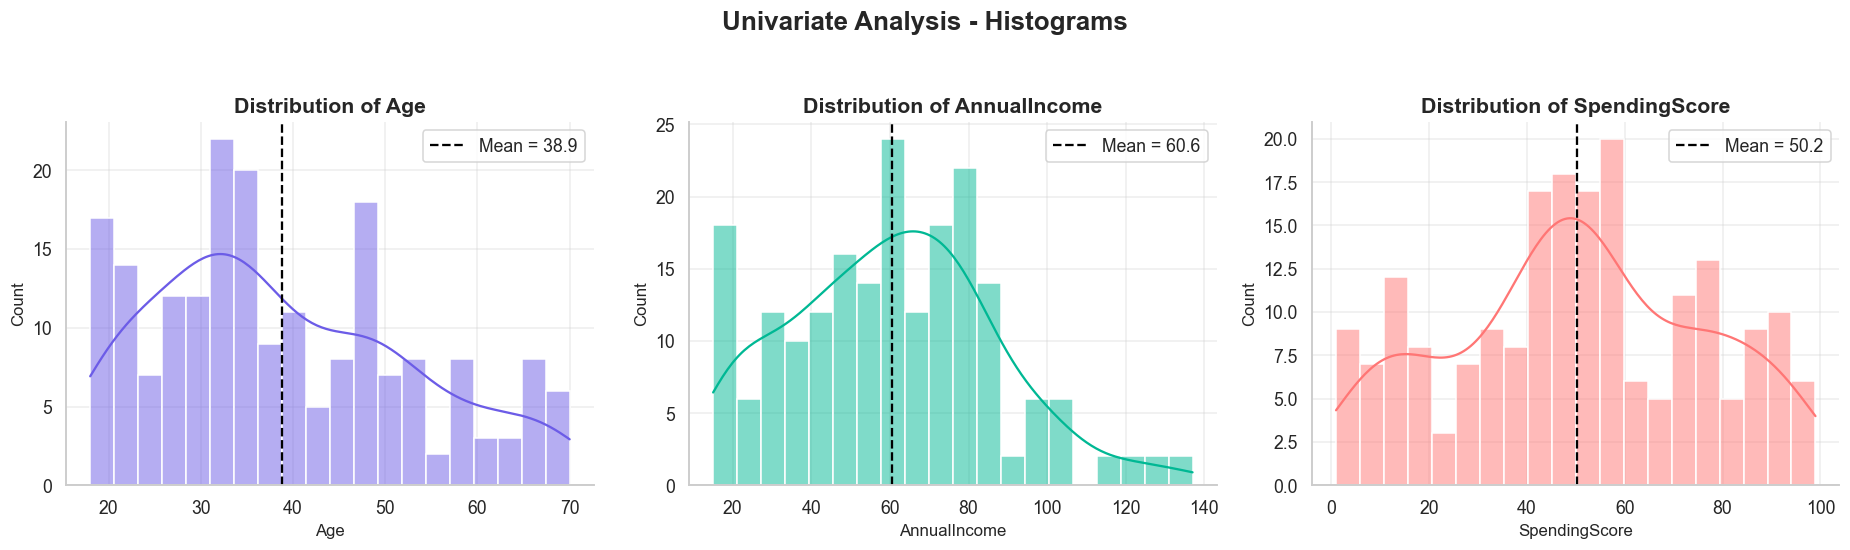

Skewness of each feature:
Age              0.49
AnnualIncome     0.32
SpendingScore   -0.05
dtype: float64


In [4]:
num_cols = ["Age", "AnnualIncome", "SpendingScore"]         
hist_colors = ["#6C5CE7", "#00B894", "#FF7675"]              

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))            

for i in range(3):
    col = num_cols[i]
    sns.histplot(df[col], kde=True, bins=20, color=hist_colors[i], edgecolor="white", ax=axes[i])

    # draw a dashed line at the average value
    mean_value = df[col].mean()
    axes[i].axvline(mean_value, color="black", linestyle="--", linewidth=1.5, label=f"Mean = {mean_value:.1f}")
    axes[i].set_title(f"Distribution of {col}")
    axes[i].legend()

fig.suptitle("Univariate Analysis - Histograms", fontsize=17, fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("01_histograms")
plt.show()

# Skewness : close to 0 means the shape is symmetric
print("Skewness of each feature:")
print(df[num_cols].skew().round(2))

**Explanation:** Histograms with a KDE curve show the shape of each variable. **Age** is right-skewed with most shoppers between roughly 25 and 50; **AnnualIncome** is fairly symmetric with a peak around 55–80 k$ and a thin right tail; **SpendingScore** is spread widely with peaks near the middle (~50) – it is a *designed* score, so it looks close to uniform/bimodal rather than bell-shaped. The skewness values printed below the plots back this up numerically (values close to 0 = symmetric).

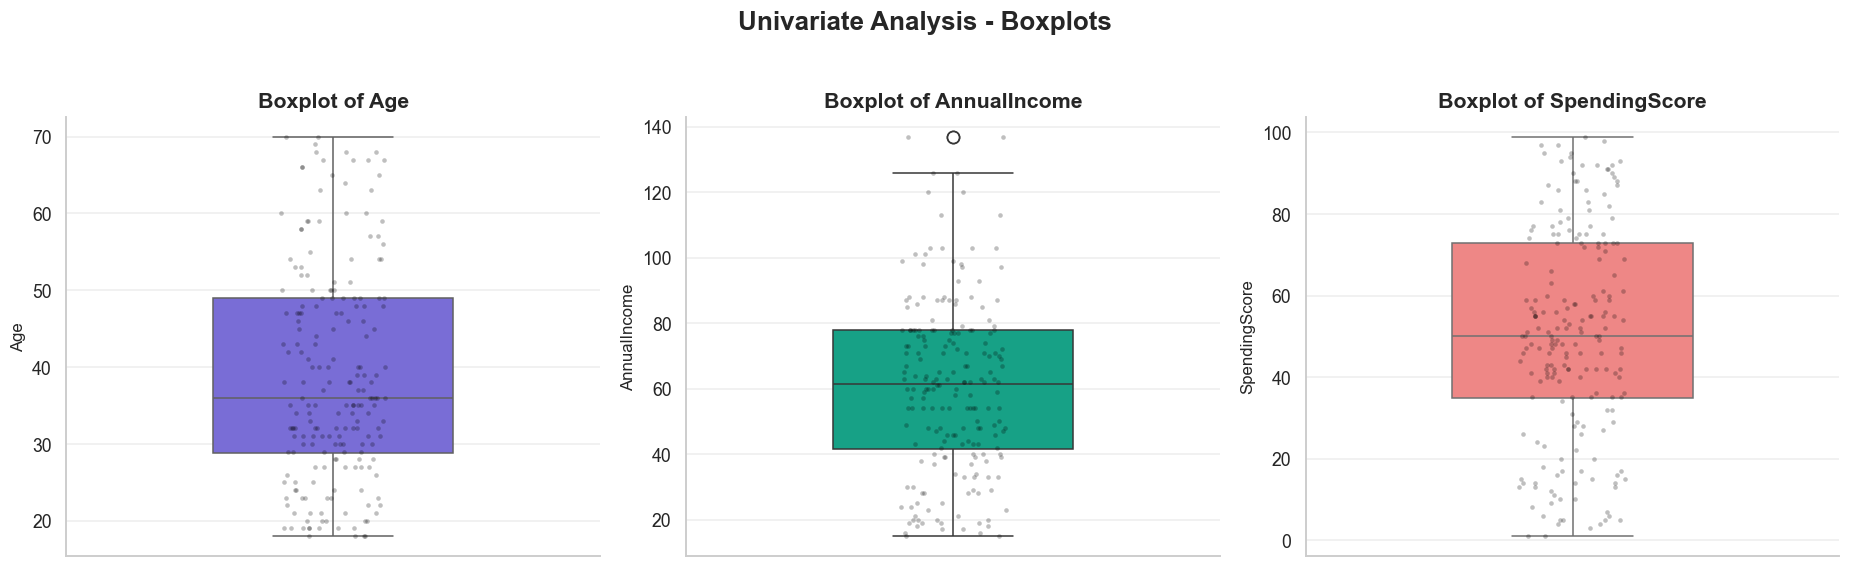

Outlier check (1.5 x IQR rule):
Age            allowed range = [  -1.6,   79.4]  ->  0 outlier(s)
AnnualIncome   allowed range = [ -13.2,  132.8]  ->  2 outlier(s)
SpendingScore  allowed range = [ -22.6,  130.4]  ->  0 outlier(s)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i in range(3):
    col = num_cols[i]
    sns.boxplot(y=df[col], color=hist_colors[i], width=0.45, fliersize=8, ax=axes[i])
    sns.stripplot(y=df[col], color="black", alpha=0.25, size=3, ax=axes[i])   # small dots = real customers
    axes[i].set_title(f"Boxplot of {col}")

fig.suptitle("Univariate Analysis - Boxplots", fontsize=17, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig("02_boxplots")
plt.show()

# Find outliers with the 1.5 x IQR rule
print("Outlier check (1.5 x IQR rule):")
for col in num_cols:
    q1 = df[col].quantile(0.25)                 # 25th percentile
    q3 = df[col].quantile(0.75)                 # 75th percentile
    iqr = q3 - q1                               # inter-quartile range
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]
    print(f"{col:14s} allowed range = [{lower_limit:6.1f}, {upper_limit:6.1f}]  ->  {len(outliers)} outlier(s)")

**Explanation:** Boxplots show the median, the inter-quartile range and any points beyond the whiskers. To avoid relying only on eyesight, the code also applies the **1.5 × IQR rule**. Only **AnnualIncome** shows a couple of high-income outliers (≈137 k$); Age and SpendingScore have none. These are genuine wealthy customers, not data errors, so they are **kept** – they are exactly the type of shopper the mall wants to understand.

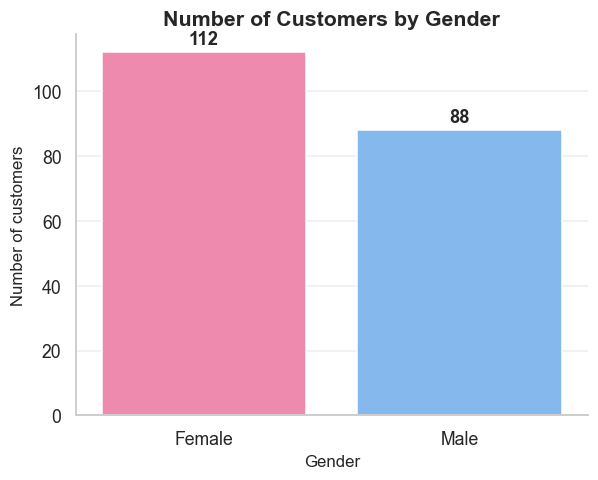

Gender
Female    56.0 %
Male      44.0 %
Name: proportion, dtype: object


In [6]:
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(data=df, x="Gender", order=["Female", "Male"], palette=["#FD79A8", "#74B9FF"])

# write the number of customers on top of each bar
for bar_group in ax.containers:
    ax.bar_label(bar_group, fontsize=12, fontweight="bold", padding=3)

plt.title("Number of Customers by Gender")
plt.ylabel("Number of customers")
save_fig("03_gender_countplot")
plt.show()

# Percentage of each gender
print((df["Gender"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

**Explanation:** The countplot makes the split visible: about **56 % female and 44 % male**. The dataset is *reasonably* balanced (not perfectly), so gender is unlikely to dominate the clustering, but we will still check its effect in the 4-feature experiment later.

## 1.3 Bivariate Analysis

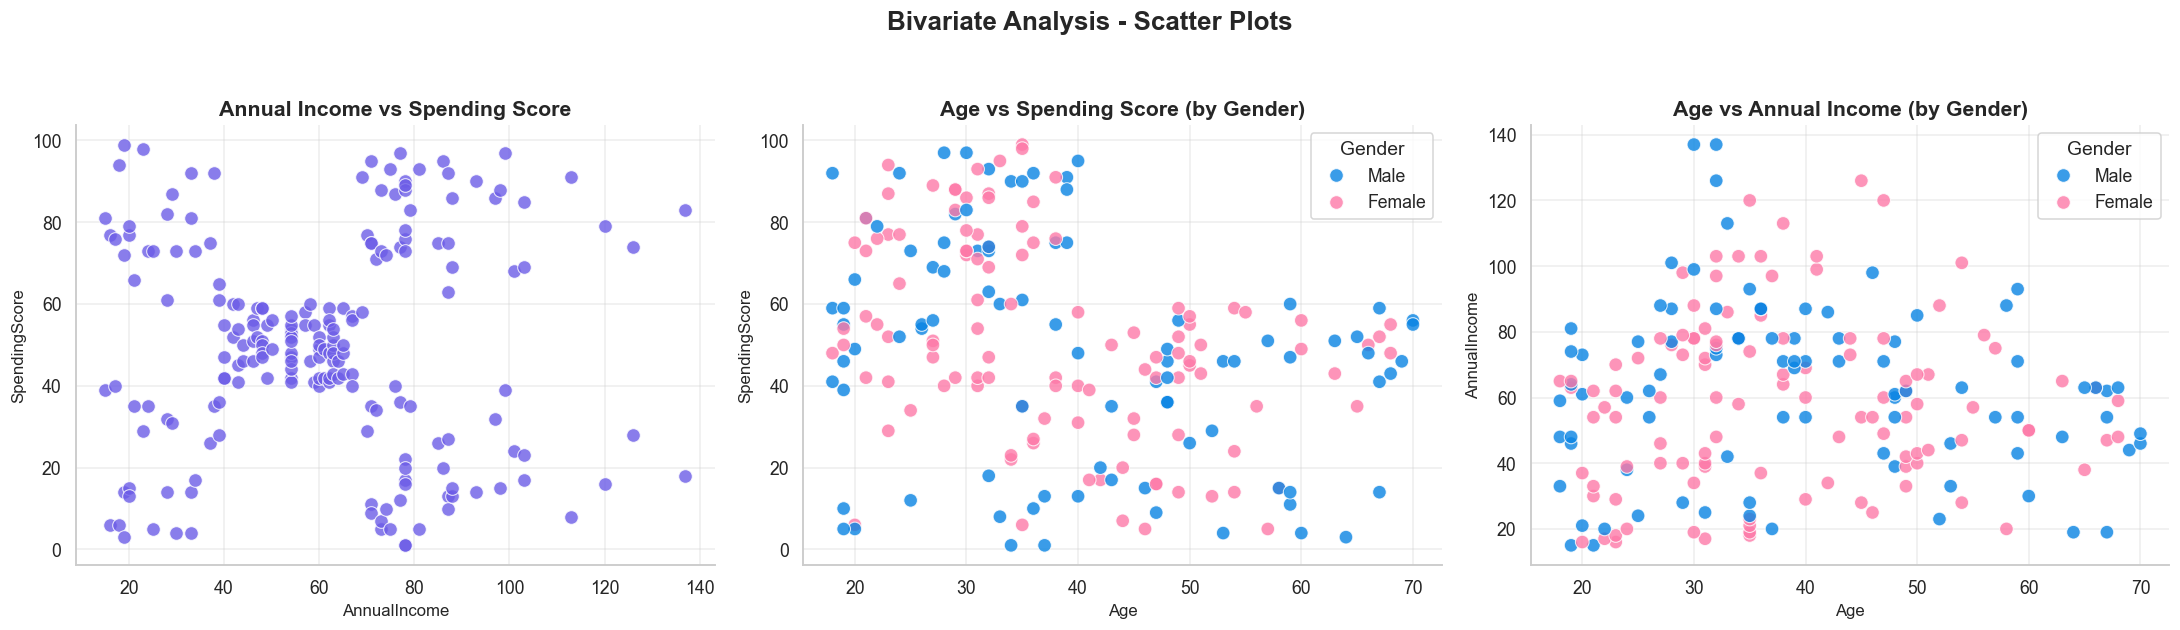

In [7]:
gender_colors = {"Female": "#FD79A8", "Male": "#0984E3"}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Graph 1: Annual Income vs Spending Score  (the main clustering canvas)
sns.scatterplot(data=df, x="AnnualIncome", y="SpendingScore", color="#6C5CE7",
                s=80, alpha=0.8, edgecolor="white", ax=axes[0])
axes[0].set_title("Annual Income vs Spending Score")

# Graph 2: Age vs Spending Score, coloured by Gender
sns.scatterplot(data=df, x="Age", y="SpendingScore", hue="Gender", palette=gender_colors,
                s=80, alpha=0.8, edgecolor="white", ax=axes[1])
axes[1].set_title("Age vs Spending Score (by Gender)")

# Graph 3: Age vs Annual Income, coloured by Gender
sns.scatterplot(data=df, x="Age", y="AnnualIncome", hue="Gender", palette=gender_colors,
                s=80, alpha=0.8, edgecolor="white", ax=axes[2])
axes[2].set_title("Age vs Annual Income (by Gender)")

fig.suptitle("Bivariate Analysis - Scatter Plots", fontsize=17, fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("04_bivariate_scatter")
plt.show()

**Explanation:** Three scatter plots explore relationships between pairs of variables.
* **Income vs Spending (left):** this is the *core clustering canvas*. Even before running any algorithm, **five separate blobs** can be seen (details in the key-insight cell below).
* **Age vs Spending (middle):** the highest spending scores (>60) are concentrated among **younger shoppers (below ~40)**, while older shoppers mostly have moderate/low scores.
* **Age vs Income (right):** no strong pattern – income is spread across all ages, with the richest customers in their late 20s–40s. Gender colours overlap heavily in all plots, so gender is not a strong separating factor.

Correlation matrix:


,Age,AnnualIncome,SpendingScore
Age,1.00,-0.01,-0.33
AnnualIncome,-0.01,1.00,0.01
SpendingScore,-0.33,0.01,1.00


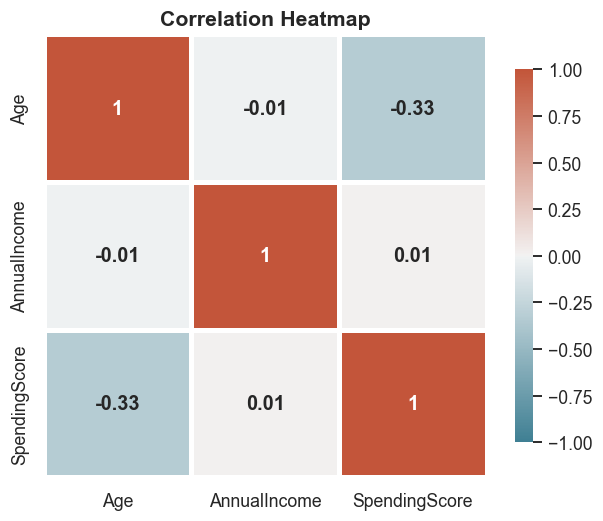

In [8]:
# CustomerID is only an identifier (a row label), so we leave it out of the correlation
corr = df[num_cols].corr().round(2)
print("Correlation matrix:")
display(corr)

# Draw the correlation matrix as a heatmap
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, annot_kws={"size": 13, "weight": "bold"},
            cmap=sns.diverging_palette(220, 20, as_cmap=True), vmin=-1, vmax=1,
            linewidths=2, linecolor="white", square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap")
save_fig("05_correlation_heatmap")
plt.show()

**Explanation:** `CustomerID` is just a row label, so it is excluded from the correlation matrix. The key numbers: **Age ↔ SpendingScore ≈ −0.33** (older customers tend to score a bit lower – the only noticeable relationship), while **AnnualIncome ↔ SpendingScore ≈ 0** and **Age ↔ AnnualIncome ≈ 0**. A near-zero *linear* correlation between income and spending does **not** mean "no structure" – the scatter plot shows clear *non-linear groups*, which is precisely why clustering is the right tool here.

## 1.4 Gender-Wise Summary

Mean values by Gender:


,Age,AnnualIncome,SpendingScore
Gender,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


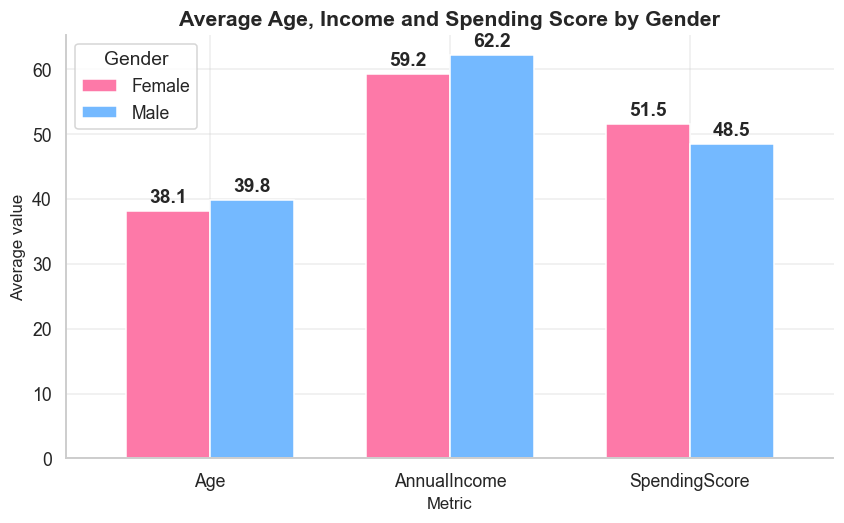

In [9]:
# Average Age, Income and Spending Score for Male and Female customers
gender_summary = df.groupby("Gender")[num_cols].mean().round(2)
print("Mean values by Gender:")
display(gender_summary)

# Grouped bar chart  (.T flips the table so the metrics come on the x-axis)
ax = gender_summary.T.plot(kind="bar", figsize=(9, 5), color=["#FD79A8", "#74B9FF"],
                           edgecolor="white", width=0.7, rot=0)
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.1f", padding=3, fontweight="bold")

plt.title("Average Age, Income and Spending Score by Gender")
plt.xlabel("Metric")
plt.ylabel("Average value")
plt.legend(title="Gender")
save_fig("06_gender_summary")
plt.show()

**Explanation:** The table and grouped bar chart compare the average profile of female and male shoppers. Differences are **small**: male customers have a slightly higher average income (≈62 vs ≈59 k$) and are marginally older (≈40 vs ≈38 years), whereas female customers have a slightly higher spending score (≈51.5 vs ≈48.5). 

### 📌 Key Insight — Can we spot the clusters before running any algorithm?
Looking at the **AnnualIncome vs SpendingScore** scatter plot, five natural groups are visible:

| # | Visual group | Income | Spending | Likely meaning |
|---|--------------|--------|----------|----------------|
| 1 | Bottom-left | Low (≈15–40 k$) | Low (≈1–40) | Budget shoppers |
| 2 | Top-left | Low (≈15–40 k$) | High (≈60–100) | Young aspirers – spend beyond their means |
| 3 | Centre | Medium (≈40–70 k$) | Medium (≈40–60) | Mainstream / average shoppers |
| 4 | Bottom-right | High (≈70–140 k$) | Low (≈1–40) | Careful spenders – wealthy but frugal |
| 5 | Top-right | High (≈70–140 k$) | High (≈60–100) | Big spenders – the premium target |

The centre group is the largest and touches its neighbours, while the four corner groups are well separated. This visual expectation of **k = 5** will be tested by K-Means, Hierarchical clustering and DBSCAN.

---
# 🔧 Step 2: Feature Engineering & Preprocessing

## 2.1 Encode the Categorical Feature

In [10]:
# Label encoding: Female -> 0 and Male -> 1
# (we keep the original Gender column for graphs and legends)
df["Gender_enc"] = df["Gender"].map({"Female": 0, "Male": 1})

# Show the mapping and check that nothing was left empty
print(df[["Gender", "Gender_enc"]].drop_duplicates().sort_values("Gender_enc").to_string(index=False))
print("\nEmpty values in Gender_enc:", df["Gender_enc"].isnull().sum())

Gender  Gender_enc
Female           0
  Male           1

Empty values in Gender_enc: 0


**Explanation:** Clustering algorithms need numbers, so `Gender` is label-encoded with an explicit mapping (**Female → 0, Male → 1**) and stored in `Gender_enc`. An explicit dictionary is used instead of `LabelEncoder` so the mapping is guaranteed and visible. The original text column is retained for readable legends in the plots. The check confirms no value was left unmapped.

## 2.2 Engineer New Features

In [39]:
# 1) IncomeGroup - 3 groups with (almost) equal number of customers (qcut = quantile cut)
df["IncomeGroup"] = pd.qcut(df["AnnualIncome"], q=3, labels=["Low", "Medium", "High"])

# 2) AgeGroup - fixed age ranges (cut = cut at the edges we choose)
#    18-25 = Young | 26-40 = Adult | 41-55 = Middle-Aged | above 55 = Senior
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 25, 40, 55, 100],
                        labels=["Young", "Adult", "Middle-Aged", "Senior"])

# 3) SpendingCategory - Low (1-33) | Medium (34-66) | High (67-100)
df["SpendingCategory"] = pd.cut(df["SpendingScore"], bins=[0, 33, 66, 100],
                                labels=["Low", "Medium", "High"])

# Print how many customers are in each group
print("IncomeGroup :-")
print(df["IncomeGroup"].value_counts().reindex(["Low", "Medium", "High"]))

print("\nAgeGroup :-")
print(df["AgeGroup"].value_counts().reindex(["Young", "Adult", "Middle-Aged", "Senior"]))

print("\nSpendingCategory :-")
print(df["SpendingCategory"].value_counts().reindex(["Low", "Medium", "High"]))

IncomeGroup :-
IncomeGroup
Low       70
Medium    64
High      66
Name: count, dtype: int64

AgeGroup :-
AgeGroup
Young          38
Adult          84
Middle-Aged    49
Senior         29
Name: count, dtype: int64

SpendingCategory :-
SpendingCategory
Low       49
Medium    94
High      57
Name: count, dtype: int64


**Explanation:** Three business-friendly categorical features are created:
* **IncomeGroup** – `pd.qcut` makes *equal-frequency* bins, so each group holds about one third of the customers (very balanced, by design).
* **AgeGroup** – `pd.cut` with fixed edges. Age 55 falls in *Middle-Aged* (bins are right-inclusive), and *Senior* means older than 55.
* **SpendingCategory** – fixed edges at 33 and 66.


IncomeGroup is balanced by construction. AgeGroup and SpendingCategory are **not** perfectly balanced because they use fixed business thresholds (e.g. very few seniors and the Adult group is the largest) – this is expected and reflects the real shape of the data. These columns are used later for *profiling and interpretation*, **not** as clustering inputs.

## 2.3 Select Features for Clustering

In [12]:
# Experiment A - 2 features
features_2d = ["AnnualIncome", "SpendingScore"]
X_2d = df[features_2d].copy()

# Experiment B - 4 features (called "5D" in the exam paper)
features_5d = ["Age", "AnnualIncome", "SpendingScore", "Gender_enc"]
X_5d = df[features_5d].copy()

print("X_2d shape:", X_2d.shape, "->", features_2d)
print("X_5d shape:", X_5d.shape, "->", features_5d)

X_2d shape: (200, 2) -> ['AnnualIncome', 'SpendingScore']
X_5d shape: (200, 4) -> ['Age', 'AnnualIncome', 'SpendingScore', 'Gender_enc']


**Explanation:** Two experiments are prepared. **Experiment A (`X_2d`)** uses only `AnnualIncome` and `SpendingScore` – the classic, easily explainable setup. **Experiment B (`X_5d`)** adds `Age` and `Gender_enc` for a richer view. *Note:* the exam calls this set "5D", but the listed features are actually **four** (Age, AnnualIncome, SpendingScore, Gender_enc); I keep the name `X_5d` to match the exam wording.

## 2.4 Scale the Features

In [13]:
# Scale the 2-feature data:  fit_transform = learn the mean/std AND apply the scaling
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# Scale the 4-feature data with its own scaler
scaler_5d = StandardScaler()
X_5d_scaled = scaler_5d.fit_transform(X_5d)

# Check: after scaling, mean should be about 0 and standard deviation about 1
check_2d = pd.DataFrame({"mean": X_2d_scaled.mean(axis=0), "std": X_2d_scaled.std(axis=0)}, index=features_2d)
check_5d = pd.DataFrame({"mean": X_5d_scaled.mean(axis=0), "std": X_5d_scaled.std(axis=0)}, index=features_5d)

print("Scaled X_2d:")
display(check_2d.round(4))
print("Scaled X_5d:")
display(check_5d.round(4))

Scaled X_2d:


,mean,std
AnnualIncome,-0.0,1.0
SpendingScore,-0.0,1.0


Scaled X_5d:


,mean,std
Age,-0.0,1.0
AnnualIncome,-0.0,1.0
SpendingScore,-0.0,1.0
Gender_enc,0.0,1.0


**Explanation:** `StandardScaler` converts every feature to *mean = 0* and *standard deviation = 1* (z-scores). This is essential because K-Means, Hierarchical clustering and DBSCAN are all **distance-based**: without scaling, `AnnualIncome` (15–137) would dominate `Age` or `Gender_enc` (0/1) in every distance calculation. The printed table confirms the scaling worked (means ≈ 0, standard deviations = 1). Separate scalers are fitted for the 2D and 4-feature matrices.

---
# 🔵 Step 3: K-Means Clustering

## 3.1 Elbow Method & Silhouette Score — Find Optimal k (on `X_2d_scaled`)

,Inertia (WCSS),Silhouette
k,,
2,269.69,0.3213
3,157.70,0.4666
4,108.92,0.4939
5,65.57,0.5547
6,55.06,0.5399
7,44.86,0.5281
8,37.23,0.4552
9,32.39,0.4571
10,29.98,0.4432


Elbow point: k = 5   |   Best silhouette (k >= 3): k = 5


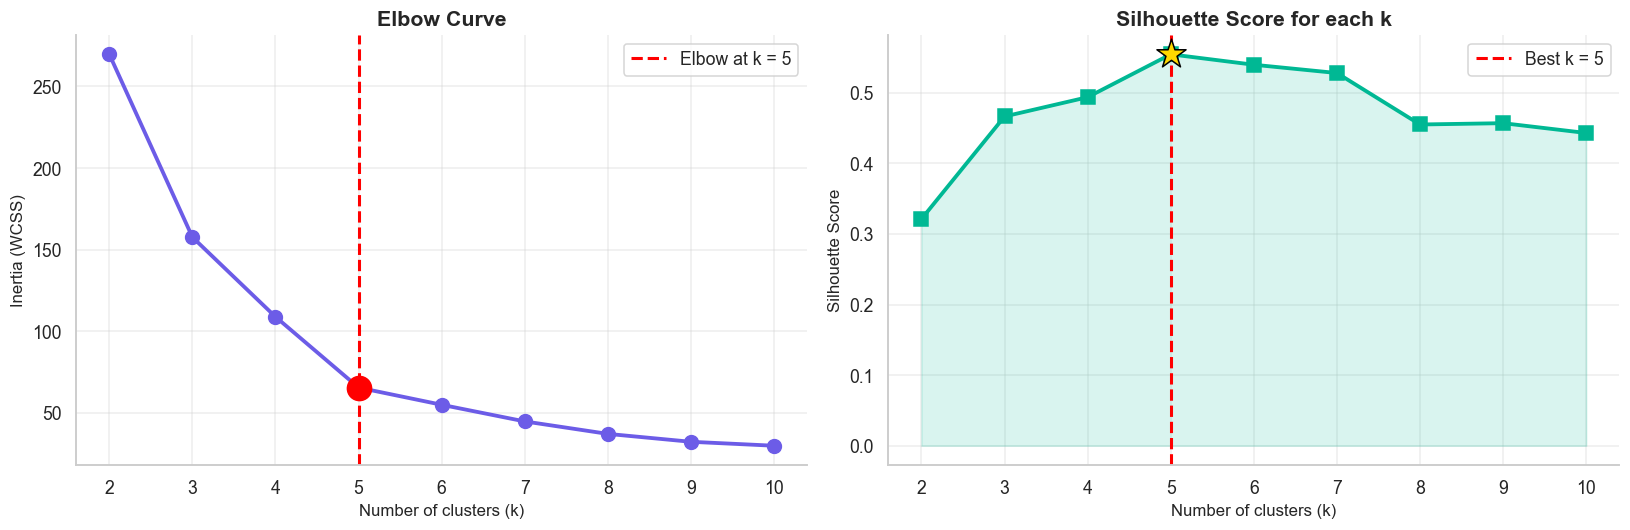

In [14]:
k_values = list(range(2, 11))        # try k = 2, 3, ... 10
inertia_list = []                    # inertia (WCSS) for each k
silhouette_list = []                 # silhouette score for each k

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_2d_scaled)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X_2d_scaled, labels))

# Elbow point (found automatically by the helper function)
elbow_k = k_values[find_elbow(k_values, inertia_list)]

# Best k = highest silhouette score. We skip k = 2 (first value) because 2 groups are too few for personas
best_index = int(np.argmax(silhouette_list[1:])) + 1
k_optimal = k_values[best_index]

# Show the numbers in a table
kmeans_scores = pd.DataFrame({"k": k_values,
                              "Inertia (WCSS)": np.round(inertia_list, 2),
                              "Silhouette": np.round(silhouette_list, 4)}).set_index("k")
display(kmeans_scores)
print(f"Elbow point: k = {elbow_k}   |   Best silhouette (k >= 3): k = {k_optimal}")

# ---- Draw both graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Elbow curve
axes[0].plot(k_values, inertia_list, marker="o", markersize=9, linewidth=2.5, color=COLORS[0])
axes[0].axvline(elbow_k, color="red", linestyle="--", linewidth=2, label=f"Elbow at k = {elbow_k}")
axes[0].scatter(elbow_k, inertia_list[k_values.index(elbow_k)], s=250, color="red", zorder=5)
axes[0].set_title("Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_xticks(k_values)
axes[0].legend()

# Right: Silhouette score
axes[1].plot(k_values, silhouette_list, marker="s", markersize=9, linewidth=2.5, color=COLORS[1])
axes[1].fill_between(k_values, silhouette_list, alpha=0.15, color=COLORS[1])
axes[1].axvline(k_optimal, color="red", linestyle="--", linewidth=2, label=f"Best k = {k_optimal}")
axes[1].scatter(k_optimal, silhouette_list[best_index], s=400, marker="*", color="gold", edgecolor="black", zorder=5)
axes[1].set_title("Silhouette Score for each k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(k_values)
axes[1].legend()

plt.tight_layout()
save_fig("07_kmeans_elbow_silhouette")
plt.show()

**Explanation :-**

 K-Means is run for k = 2 … 10 using `k-means++` initialisation. For each k the code stores the **inertia** (within-cluster sum of squares) and the **silhouette score**. The *elbow* is located automatically as the point furthest from the straight line joining the first and last points of the inertia curve, and is marked with a red dashed line. The optimal k is the one with the **highest silhouette among k ≥ 3** (k = 2 is too coarse to create useful retail personas).

**Justification :-**

 On this dataset the inertia curve bends sharply at **k = 5** and the silhouette score peaks at **k = 5** as well (≈ 0.55). Both methods agree, and k = 5 also matches the five visual groups spotted in the EDA, so **`k_optimal = 5`** is selected. (If your run shows a different value, keep the code as it is and simply justify the number the two plots give.)

## 3.2 Train the Final K-Means Models (2D and 4-feature)

In [15]:
# Model 1: K-Means on 2 features (Income, Spending)
kmeans_2d = KMeans(n_clusters=k_optimal, init="k-means++", n_init=20, max_iter=500, random_state=RANDOM_STATE)
df["KMeans_Cluster"] = kmeans_2d.fit_predict(X_2d_scaled)          # cluster number of every customer

# Model 2: K-Means on 4 features (Age, Income, Spending, Gender)
kmeans_5d = KMeans(n_clusters=k_optimal, init="k-means++", n_init=20, max_iter=500, random_state=RANDOM_STATE)
df["KMeans_5D_Cluster"] = kmeans_5d.fit_predict(X_5d_scaled)

# Compare the silhouette scores (higher = better separated clusters)
sil_2d = silhouette_score(X_2d_scaled, df["KMeans_Cluster"])
sil_5d = silhouette_score(X_5d_scaled, df["KMeans_5D_Cluster"])

comparison_dim = pd.DataFrame({
    "Feature set": ["2D  (Income, Spending)", "5D  (Age, Income, Spending, Gender)"],
    "Silhouette Score": [round(sil_2d, 4), round(sil_5d, 4)],
}).set_index("Feature set")
display(comparison_dim)

if sil_2d > sil_5d:
    winner = "2D"
else:
    winner = "5D"
print(f"➡ The {winner} feature set gives better-separated clusters.")

print("\nCluster sizes (2D):", df["KMeans_Cluster"].value_counts().sort_index().to_dict())
print("Cluster sizes (5D):", df["KMeans_5D_Cluster"].value_counts().sort_index().to_dict())

,Silhouette Score
Feature set,
"2D (Income, Spending)",0.5547
"5D (Age, Income, Spending, Gender)",0.3144


➡ The 2D feature set gives better-separated clusters.

Cluster sizes (2D): {0: 81, 1: 39, 2: 22, 3: 35, 4: 23}
Cluster sizes (5D): {0: 48, 1: 39, 2: 28, 3: 29, 4: 56}


**Explanation :-**

 The same K-Means configuration (`k-means++`, `n_init=20`, `max_iter=500`, `random_state=42`) is trained on both feature sets and the labels are stored as `KMeans_Cluster` and `KMeans_5D_Cluster`. The **2D model has the higher silhouette score** (around 0.55 versus a clearly lower value for the richer set), meaning the income–spending plane holds the cleanest group structure. Adding `Age` and `Gender_enc` adds dimensions in which the data does *not* form tight groups, so cohesion drops. Therefore **2D is the primary model** for the rest of the project, while the 5D result is used for a richer demographic view.

## 3.3 Visualise the K-Means Clusters

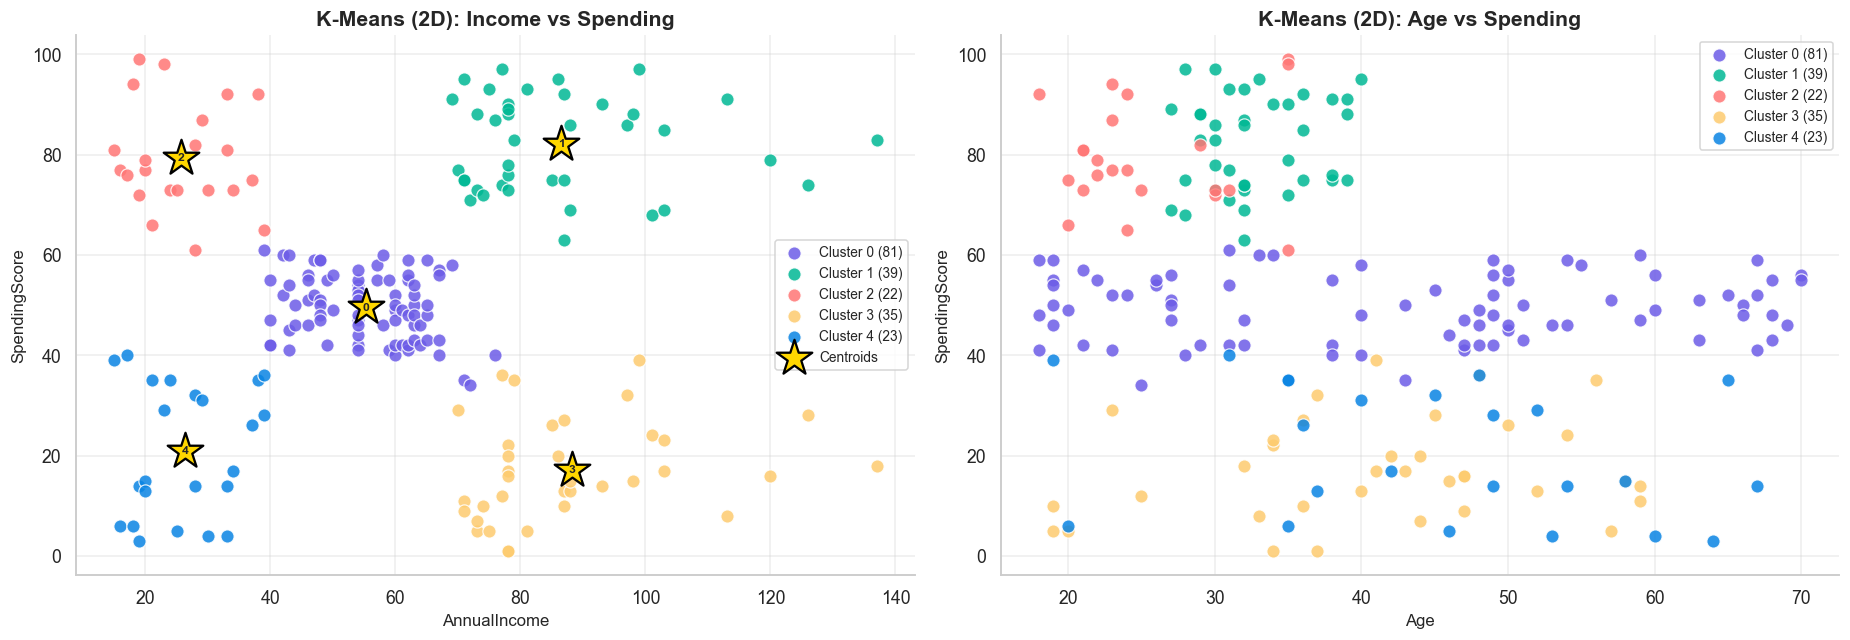

In [16]:
# The centroids were calculated on scaled data, so convert them back to real income / spending values
centers_2d = scaler_2d.inverse_transform(kmeans_2d.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_clusters(axes[0], df, "AnnualIncome", "SpendingScore", "KMeans_Cluster",
              "K-Means (2D): Income vs Spending", centers=centers_2d)
plot_clusters(axes[1], df, "Age", "SpendingScore", "KMeans_Cluster",
              "K-Means (2D): Age vs Spending")

plt.tight_layout()
save_fig("08_kmeans_clusters")
plt.show()

**Explanation :-** 

The left plot is the main result: five well-separated groups on the Income–Spending canvas, with each **★** marking the centroid (converted back from scaled values to real income/spending units). The right plot re-uses the same colours on Age vs Spending – it shows that some clusters are also age-driven (for example the low-income / high-spending group is clearly **younger**), even though age was *not* used to form them.

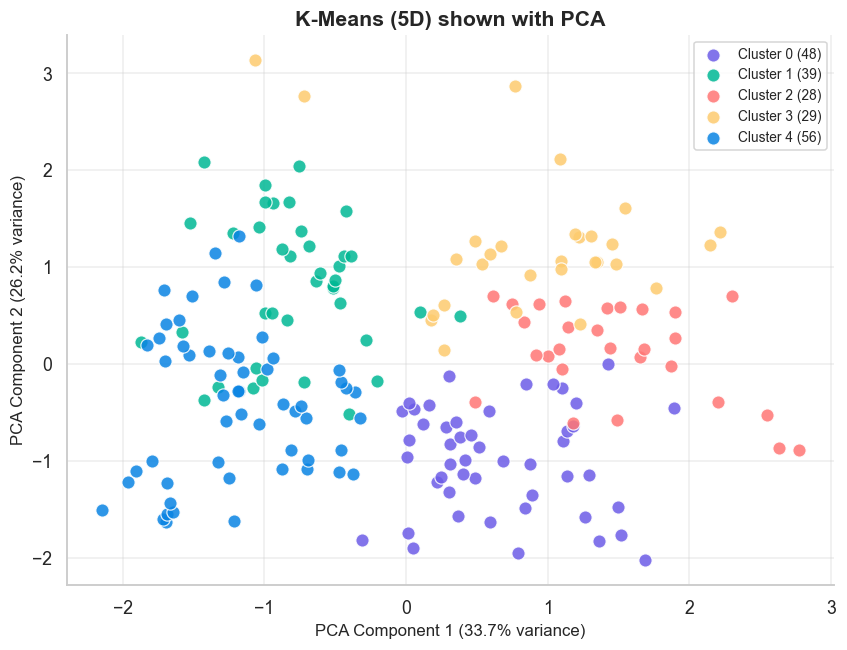

Total variance explained by the 2 components: 59.9%


In [17]:
# PCA squeezes the 4 features into 2 components so that we can draw a 2D picture
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_result = pca.fit_transform(X_5d_scaled)

df["PCA1"] = pca_result[:, 0]
df["PCA2"] = pca_result[:, 1]

# How much information does each component keep? (in %)
var1 = pca.explained_variance_ratio_[0] * 100
var2 = pca.explained_variance_ratio_[1] * 100

fig, ax = plt.subplots(figsize=(9, 6.5))
plot_clusters(ax, df, "PCA1", "PCA2", "KMeans_5D_Cluster", "K-Means (5D) shown with PCA")
ax.set_xlabel(f"PCA Component 1 ({var1:.1f}% variance)")
ax.set_ylabel(f"PCA Component 2 ({var2:.1f}% variance)")
save_fig("09_kmeans_5d_pca")
plt.show()

print(f"Total variance explained by the 2 components: {var1 + var2:.1f}%")

**Explanation :-** 

Four-dimensional data cannot be plotted directly, so **PCA** compresses it into two components; the axis labels show how much variance each keeps. The clusters look less clean-cut here than in the 2D plot because part of the information (the remaining variance) is lost in the projection and because the binary `Gender_enc` splits the cloud into two "layers". This matches the lower silhouette score found in 3.2.

In [18]:
# Optional: an interactive graph (hover over a point to see Age and Gender)
try:
    import plotly.express as px
    plot_df = df.copy()
    plot_df["Cluster"] = plot_df["KMeans_Cluster"].astype(str)          # text, so each cluster gets its own colour
    fig = px.scatter(plot_df, x="AnnualIncome", y="SpendingScore", color="Cluster",
                     hover_data=["Age", "Gender"], color_discrete_sequence=COLORS,
                     title="Interactive K-Means clusters (2D)")
    fig.update_traces(marker=dict(size=10, line=dict(width=1, color="white")))
    fig.show()
except Exception as error:
    print("Plotly graph skipped:", error)

**Explanation :-** 

An optional interactive chart (hover to see Age and Gender of each shopper). It uses `plotly`, which is listed in `requirements.txt`; the cell is wrapped in `try/except` so the notebook never stops if Plotly's renderer is unavailable.

## 3.4 Profile the K-Means Clusters & Assign Retail Personas

In [19]:
# ------------------------------------------------------------
# Step A: A function that gives a persona name to a cluster
#         using the cluster's AVERAGE income and AVERAGE spending score
# ------------------------------------------------------------
def get_persona(income, spending):
    # Decide the income level
    if income < 40:
        income_level = "Low"
    elif income < 70:
        income_level = "Medium"
    else:
        income_level = "High"

    # Decide the spending level
    if spending < 35:
        spending_level = "Low"
    elif spending < 65:
        spending_level = "Medium"
    else:
        spending_level = "High"

    # Combine both levels to get the persona
    if income_level == "High" and spending_level == "High":
        return "Big Spenders"
    elif income_level == "High" and spending_level == "Medium":
        return "Selective Spenders"
    elif income_level == "High" and spending_level == "Low":
        return "Careful Spenders"
    elif income_level == "Medium" and spending_level == "High":
        return "Enthusiastic Shoppers"
    elif income_level == "Medium" and spending_level == "Medium":
        return "Mainstream Shoppers"
    elif income_level == "Medium" and spending_level == "Low":
        return "Value Seekers"
    elif income_level == "Low" and spending_level == "High":
        return "Young Aspirers"
    elif income_level == "Low" and spending_level == "Medium":
        return "Occasional Shoppers"
    else:
        return "Budget Shoppers"


# ------------------------------------------------------------
# Step B: One-line description and one retail strategy for every persona
# ------------------------------------------------------------
PERSONA_INFO = {
    "Big Spenders": ("High income and high spending - the premium core of the mall.",
                     "Install a premium lounge with curated luxury-brand pop-ups near the food court, plus invite-only previews and personal-shopper service."),
    "Selective Spenders": ("High income with moderate spending - buy only when the offer is right.",
                           "Run private sale evenings and brand-launch invitations through the mall app to convert more of their wallet."),
    "Careful Spenders": ("High income but low spending - wealthy yet frugal, an untapped opportunity.",
                         "Use quality- and warranty-led messaging, premium electronics/home showcases and personalised app offers to raise their visit value."),
    "Enthusiastic Shoppers": ("Medium income, high spending - frequent, engaged buyers.",
                              "Offer loyalty-point multipliers on weekends and lifestyle/food events to keep the visit frequency high."),
    "Mainstream Shoppers": ("Medium income and medium spending - the largest 'Westside-type' everyday segment.",
                            "Place mid-range brand zones around the central atrium and run seasonal sales and family bundle offers."),
    "Value Seekers": ("Medium income but low spending - price-conscious comparison shoppers.",
                      "Promote value-fashion and hypermarket deals with cashback and coupon offers in the mall app."),
    "Young Aspirers": ("Low income but very high spending - young, trend-driven shoppers.",
                       "Create a youth zone (fast fashion, gaming, cafes) with student discounts, UPI cashback and Instagram-worthy pop-ups."),
    "Occasional Shoppers": ("Low income, medium spending - visit for specific needs or festivals.",
                            "Time festival-season promotions and food-court combo offers to increase visit frequency."),
    "Budget Shoppers": ("Low income and low spending - value-for-money and deal seekers.",
                        "Place value-for-money stores near mall entrances and send ₹50-off coupons and BOGO offers via the mall app."),
}


def get_info(persona):
    """Return (description, strategy) of a persona. Works even if the name ends with '(Segment n)'."""
    base_name = persona.split(" (Segment")[0]
    return PERSONA_INFO[base_name]


# ------------------------------------------------------------
# Step C: Name every cluster of a profile table
# ------------------------------------------------------------
def name_personas(profile):
    """profile = table with one row per cluster (row label = cluster number).
       Returns a dictionary like {0: 'Big Spenders', 1: 'Budget Shoppers', ...}"""
    persona_map = {}
    for cluster_id, row in profile.iterrows():
        persona_map[cluster_id] = get_persona(row["AnnualIncome"], row["SpendingScore"])

    # If two clusters got the same name, add the cluster number so they can be told apart
    all_names = list(persona_map.values())
    for cluster_id in persona_map:
        if all_names.count(persona_map[cluster_id]) > 1:
            persona_map[cluster_id] = f"{persona_map[cluster_id]} (Segment {cluster_id})"
    return persona_map


print("Persona functions ready ✅")

Persona functions ready ✅


**Explanation :-** 

Before profiling, this cell builds a small **persona toolkit** :-


* `get_persona()` looks at a cluster's *average income* (Low < 40 k$, High ≥ 70 k$) and *average spending score* (Low < 35, High ≥ 65) using simple `if / elif` rules and returns a name such as *Big Spenders* or *Budget Shoppers*.
* `PERSONA_INFO` stores a one-line description and a concrete retail strategy for every persona (reused in Step 6.3).
* `name_personas()` applies the rules to every cluster of a profile table. If two clusters ever get the same name, the cluster number is added.

The same rules are used for K-Means, Hierarchical clustering and DBSCAN, so naming is **consistent and data-driven**.

K-Means cluster profile (sorted by SpendingScore):


,Customers,Age,AnnualIncome,SpendingScore
KMeans_Cluster,,,,
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
0,81,42.72,55.30,49.52
4,23,45.22,26.30,20.91
3,35,41.11,88.20,17.11



Gender split per cluster:


,% Female,% Male
KMeans_Cluster,,
1,53.8,46.2
2,59.1,40.9
0,59.3,40.7
4,60.9,39.1
3,45.7,54.3



Persona of each cluster:


,Customers,AnnualIncome,SpendingScore,Persona
KMeans_Cluster,,,,
1,39,86.54,82.13,Big Spenders
2,22,25.73,79.36,Young Aspirers
0,81,55.30,49.52,Mainstream Shoppers
4,23,26.30,20.91,Budget Shoppers
3,35,88.20,17.11,Careful Spenders


Justification:
* Cluster 1 -> Big Spenders: income 87k$, spending score 82, age 33 (39 customers). High income and high spending - the premium core of the mall.
* Cluster 2 -> Young Aspirers: income 26k$, spending score 79, age 25 (22 customers). Low income but very high spending - young, trend-driven shoppers.
* Cluster 0 -> Mainstream Shoppers: income 55k$, spending score 50, age 43 (81 customers). Medium income and medium spending - the largest 'Westside-type' everyday segment.
* Cluster 4 -> Budget Shoppers: income 26k$, spending score 21, age 45 (23 customers). Low income and low spending - value-for-money and deal seekers.
* Cluster 3 -> Careful Spenders: income 88k$, spending score 17, age 41 (35 customers). High income but low spending - wealthy yet frugal, an untapped opportunity.


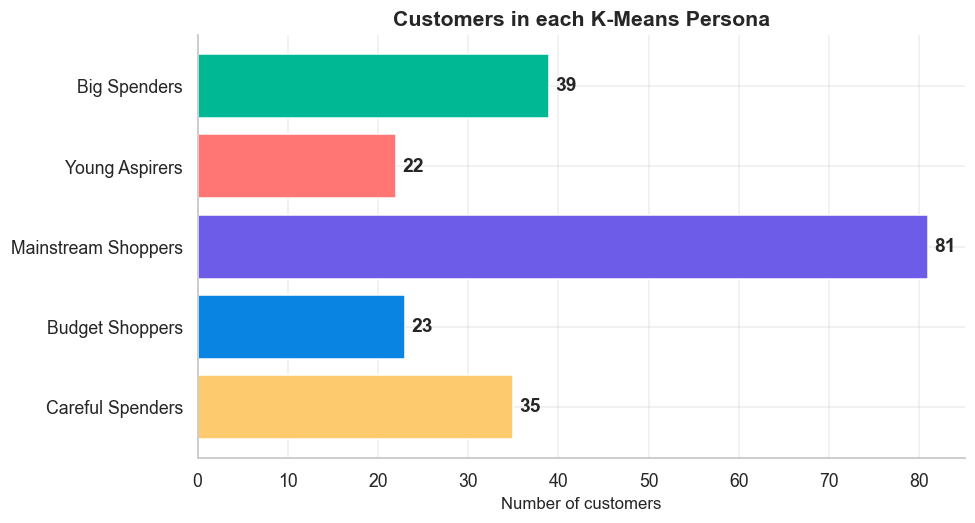

In [ ]:
# 1) Average Age, Income and Spending of every cluster (real, unscaled values)
km_profile = df.groupby("KMeans_Cluster").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    AnnualIncome=("AnnualIncome", "mean"),
    SpendingScore=("SpendingScore", "mean"),
).round(2)

km_profile = km_profile.sort_values("SpendingScore", ascending=False)      # biggest spenders first
print("K-Means cluster profile (sorted by SpendingScore):")
display(km_profile)

# 2) Male / Female percentage in every cluster
gender_split = pd.crosstab(df["KMeans_Cluster"], df["Gender"], normalize="index") * 100
gender_split = gender_split.round(1)
gender_split.columns = ["% " + name for name in gender_split.columns]
print("\nGender split per cluster:")
display(gender_split.loc[km_profile.index])

# 3) Give a persona to every cluster
km_persona_map = name_personas(km_profile)
df["KMeans_Persona"] = df["KMeans_Cluster"].map(km_persona_map)
km_profile["Persona"] = km_profile.index.map(km_persona_map)

print("\nPersona of each cluster:")
display(km_profile[["Customers", "AnnualIncome", "SpendingScore", "Persona"]])

# 4) Explain every persona in one sentence
print("Justification:")
for cluster_id, row in km_profile.iterrows():
    description = get_info(row["Persona"])[0]
    print(f"* Cluster {cluster_id} -> {row['Persona']}: income {row['AnnualIncome']:.0f}k$, "
          f"spending score {row['SpendingScore']:.0f}, age {row['Age']:.0f} ({int(row['Customers'])} customers). {description}")

# 5) A quick picture of the personas
plt.figure(figsize=(9, 5))
bar_colors = [COLORS[i % len(COLORS)] for i in km_profile.index]
bars = plt.barh(km_profile["Persona"], km_profile["Customers"], color=bar_colors, edgecolor="white")
plt.bar_label(bars, padding=4, fontweight="bold")
plt.gca().invert_yaxis()
plt.title("Customers in each K-Means Persona")
plt.xlabel("Number of customers")
save_fig("08b_kmeans_personas")
plt.show()

**Explanation :-** 

The profile table shows the **unscaled average Age, AnnualIncome and SpendingScore** of each cluster, sorted from highest to lowest spender, together with the male/female percentage of each group. A small bar chart shows how many customers fall in each persona. The persona is then assigned automatically and justified in one sentence per cluster. Typical outcome for this dataset:

* **Big Spenders** – income ≈ 87 k$, score ≈ 82 → the **Zara / premium-brand** shopper, best placed in premium brand zones.
* **Young Aspirers** – income ≈ 26 k$, score ≈ 79, average age in the mid-20s → trend-driven, spend more than they earn.
* **Mainstream Shoppers** – income ≈ 55 k$, score ≈ 50 → the **Westside-type** everyday shopper and the largest group.
* **Careful Spenders** – income ≈ 88 k$, score ≈ 17 → wealthy but hard to convert.
* **Budget Shoppers** – income ≈ 26 k$, score ≈ 21 → the BOGO / discount seeker.

Gender is close to a 55 : 45 (female : male) split in every cluster, confirming that gender does not define the segments.

---
# 🌳 Step 4: Agglomerative Hierarchical Clustering

## 4.1 Dendrogram Analysis (on `X_2d_scaled`)

Largest gap = 5.10  ->  cutting into 5 clusters
Horizontal cut line drawn at distance ~ 6.90


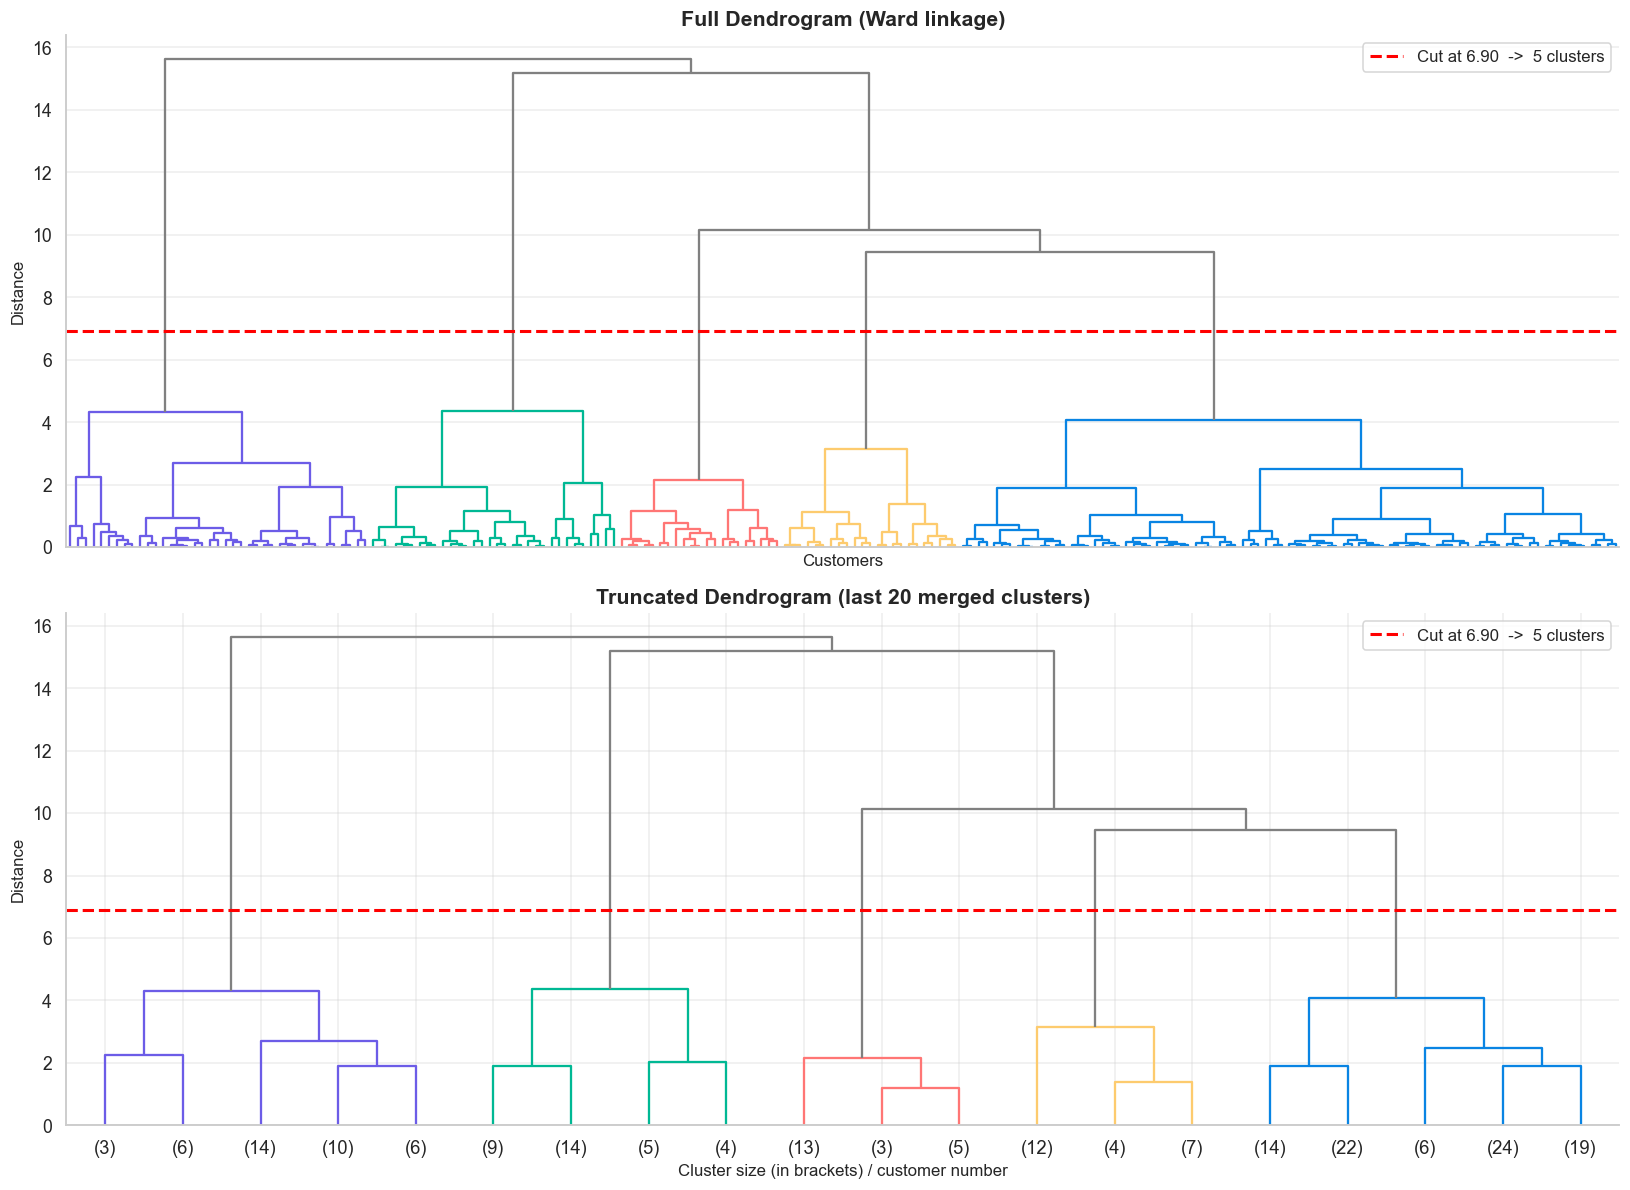

In [40]:
# Step 1: Build the hierarchy with Ward linkage
Z = linkage(X_2d_scaled, method="ward")
n_points = len(X_2d_scaled)
merge_heights = Z[:, 2]                # the distance at which each merge happened (small -> large)

# Step 2: Find the "longest vertical line that no horizontal line crosses".
#         If we cut the tree into n clusters, the cut passes through the gap between two merge heights.
#         The BIGGEST gap = the most natural number of clusters.
#         (we test n = 3 to 10, because 2 clusters are too few for retail personas)
best_gap = 0
n_chosen = 5
for n in range(3, 11):
    upper_height = merge_heights[n_points - n]
    lower_height = merge_heights[n_points - n - 1]
    gap = upper_height - lower_height
    if gap > best_gap:
        best_gap = gap
        n_chosen = n

# Step 3: Draw the cut line in the middle of the biggest gap
cut_distance = (merge_heights[n_points - n_chosen] + merge_heights[n_points - n_chosen - 1]) / 2
print(f"Largest gap = {best_gap:.2f}  ->  cutting into {n_chosen} clusters")
print(f"Horizontal cut line drawn at distance ~ {cut_distance:.2f}")

# Step 4: Plot the dendrogram twice (full and truncated)
set_link_color_palette(COLORS)                 
fig, axes = plt.subplots(2, 1, figsize=(15, 11))

dendrogram(Z, no_labels=True, color_threshold=cut_distance, above_threshold_color="grey", ax=axes[0])
axes[0].axhline(cut_distance, color="red", linestyle="--", linewidth=2,
                label=f"Cut at {cut_distance:.2f}  ->  {n_chosen} clusters")
axes[0].set_title("Full Dendrogram (Ward linkage)")
axes[0].set_xlabel("Customers")
axes[0].set_ylabel("Distance")
axes[0].legend(fontsize=11)

dendrogram(Z, truncate_mode="lastp", p=20, show_leaf_counts=True,
           color_threshold=cut_distance, above_threshold_color="grey", ax=axes[1])
axes[1].axhline(cut_distance, color="red", linestyle="--", linewidth=2,
                label=f"Cut at {cut_distance:.2f}  ->  {n_chosen} clusters")
axes[1].set_title("Truncated Dendrogram (last 20 merged clusters)")
axes[1].set_xlabel("Cluster size (in brackets) / customer number")
axes[1].set_ylabel("Distance")
axes[1].legend(fontsize=11)

plt.tight_layout()
save_fig("10_dendrogram")
plt.show()

**Explanation :-** 

`linkage(..., method="ward")` builds the merge tree by always joining the two clusters that increase the within-cluster variance the least. The dendrogram is plotted twice – in full (200 leaves) and truncated to the last 20 merges for a cleaner view. To find the natural number of clusters the code measures the **vertical gap between consecutive merge heights** and cuts through the *longest gap* (the longest vertical line not crossed by any horizontal line). The red dashed line is the cut; the printed cut distance and cluster count give the natural number of clusters – on this dataset that is **5**, in agreement with K-Means. (Cuts giving only 2 clusters are ignored on purpose because two segments are too coarse for targeted marketing.)

## 4.2 Train Agglomerative Models & Compare Linkage Methods

In [22]:
# Train 3 hierarchical models that differ only in the linkage method
linkage_methods = ["ward", "complete", "average"]
all_labels = {}                        # cluster labels of each method
silhouette_by_method = {}              # silhouette score of each method

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=n_chosen, linkage=method)
    labels = model.fit_predict(X_2d_scaled)
    all_labels[method] = labels
    silhouette_by_method[method] = round(silhouette_score(X_2d_scaled, labels), 4)

# Comparison table
linkage_table = pd.DataFrame({"Silhouette Score": silhouette_by_method})
linkage_table.index.name = "Linkage"
print(f"Silhouette comparison for n_clusters = {n_chosen}:")
display(linkage_table)

# Pick the method with the highest silhouette score
best_linkage = linkage_table["Silhouette Score"].idxmax()
print(f"➡ Best linkage method: '{best_linkage}'")

df["Agg_Cluster"] = all_labels[best_linkage]
print("\nAgg_Cluster sizes:", df["Agg_Cluster"].value_counts().sort_index().to_dict())

Silhouette comparison for n_clusters = 5:


,Silhouette Score
Linkage,
ward,0.5538
complete,0.5531
average,0.4794


➡ Best linkage method: 'ward'

Agg_Cluster sizes: {0: 32, 1: 39, 2: 85, 3: 21, 4: 23}


**Explanation :-** 

The same number of clusters is trained with three linkage rules – **ward** (minimises variance), **complete** (max distance between clusters) and **average** (mean distance). The comparison table ranks them by silhouette score and the best one is used to create `Agg_Cluster`. For compact, blob-like data such as this, **Ward usually wins** (or ties very closely with average), because it favours equally-sized, round clusters.

## 4.3 Visualise & Profile the Hierarchical Clusters

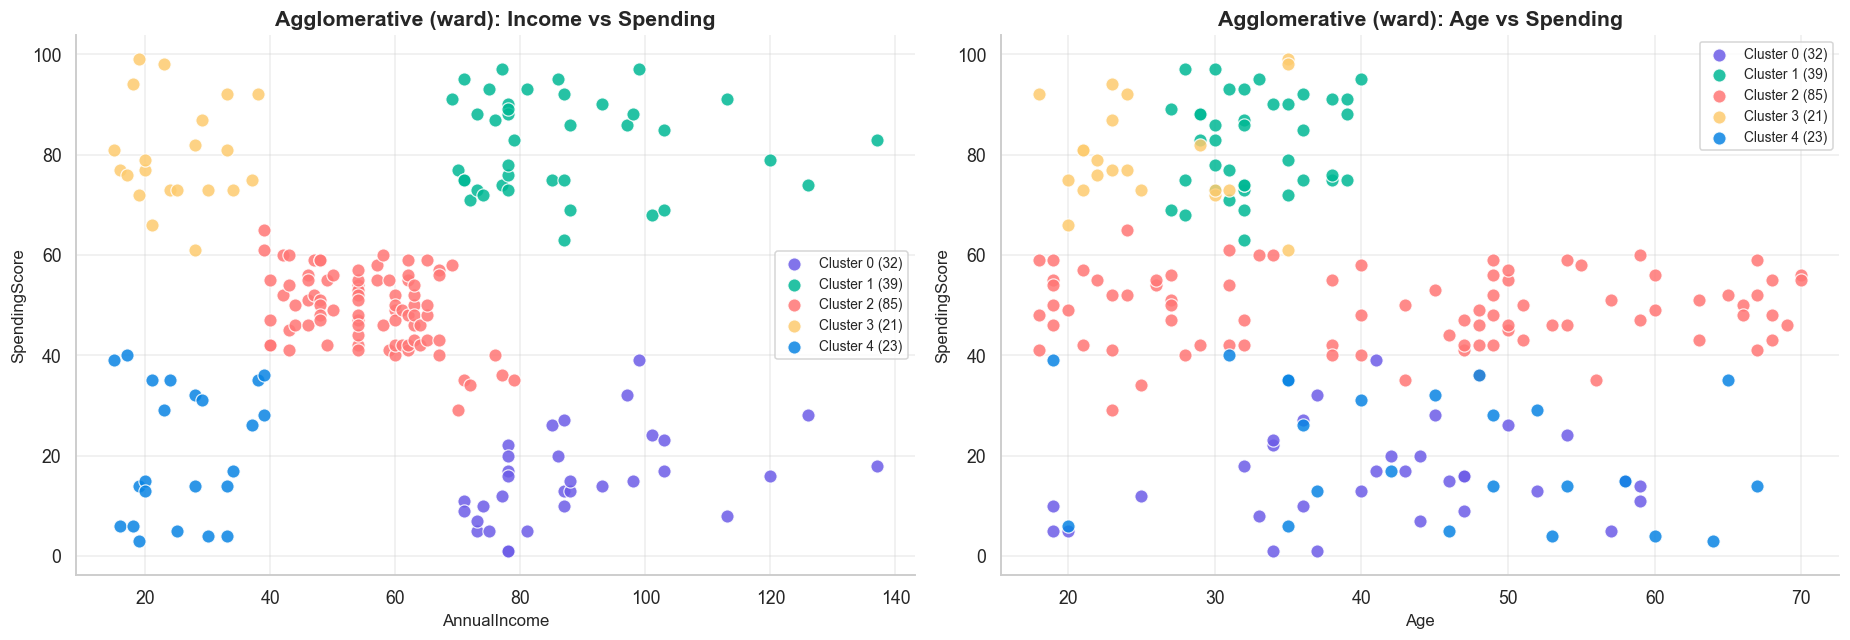

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_clusters(axes[0], df, "AnnualIncome", "SpendingScore", "Agg_Cluster",
              f"Agglomerative ({best_linkage}): Income vs Spending")
plot_clusters(axes[1], df, "Age", "SpendingScore", "Agg_Cluster",
              f"Agglomerative ({best_linkage}): Age vs Spending")

plt.tight_layout()
save_fig("11_agglomerative_clusters")
plt.show()

**Explanation :-** 

Both scatter plots colour customers by their hierarchical cluster. The Income–Spending view shows the same five blocks found by K-Means (cluster numbers/colours may differ because labels are arbitrary), and the Age view again shows the youngest customers in the high-spending / low-income group.

Hierarchical cluster profile:


,Customers,Age,AnnualIncome,SpendingScore,Persona
Agg_Cluster,,,,,
1,39,32.69,86.54,82.13,Big Spenders
3,21,25.33,25.10,80.05,Young Aspirers
2,85,42.48,55.81,49.13,Mainstream Shoppers
4,23,45.22,26.30,20.91,Budget Shoppers
0,32,41.00,89.41,15.59,Careful Spenders



Contingency table (rows = K-Means, columns = Hierarchical):


Agg_Cluster,0,1,2,3,4
KMeans_Cluster,,,,,
0,0,0,81,0,0
1,0,39,0,0,0
2,0,0,1,21,0
3,32,0,3,0,0
4,0,0,0,0,23


Customers placed in the same cluster by both algorithms: 196 out of 200  ->  agreement = 98.0%
Adjusted Rand Index = 0.942   (1.0 means both algorithms give identical groups)


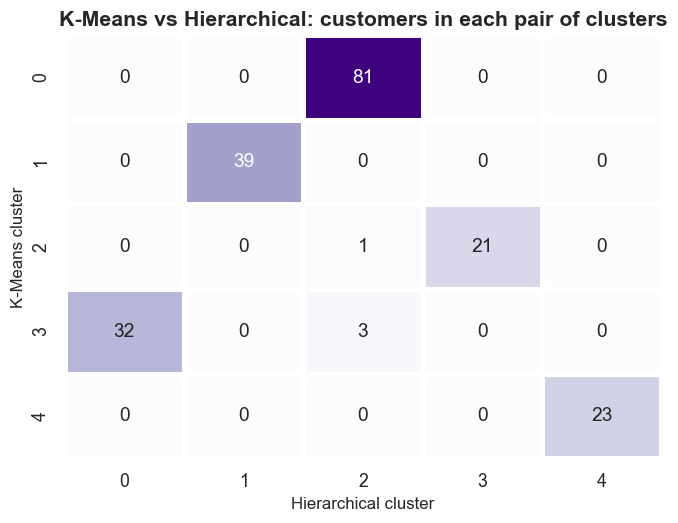

In [41]:
# Profile of the hierarchical clusters
agg_profile = df.groupby("Agg_Cluster").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    AnnualIncome=("AnnualIncome", "mean"),
    SpendingScore=("SpendingScore", "mean"),
).round(2)
agg_profile = agg_profile.sort_values("SpendingScore", ascending=False)

agg_persona_map = name_personas(agg_profile)
df["Agg_Persona"] = df["Agg_Cluster"].map(agg_persona_map)
agg_profile["Persona"] = agg_profile.index.map(agg_persona_map)

print("Hierarchical cluster profile:")
display(agg_profile)


# How much do K-Means and Hierarchical agree?
# Cluster numbers are only labels (cluster 0 in K-Means may be cluster 3 in Hierarchical),
# so first we find which cluster of one algorithm matches which cluster of the other.
def cluster_agreement(labels_a, labels_b):
    table = pd.crosstab(labels_a, labels_b)                      # how many customers share each pair of clusters
    rows, cols = linear_sum_assignment(-table.values)            # best one-to-one matching of clusters
    matched_customers = table.values[rows, cols].sum()           # customers that sit in matched clusters
    return matched_customers / len(labels_a) * 100, table


agreement_pct, contingency = cluster_agreement(df["KMeans_Cluster"], df["Agg_Cluster"])
ari = adjusted_rand_score(df["KMeans_Cluster"], df["Agg_Cluster"])

print("\nContingency table (rows = K-Means, columns = Hierarchical):")
display(contingency)
print(f"Customers placed in the same cluster by both algorithms: "
      f"{int(round(agreement_pct * len(df) / 100))} out of {len(df)}  ->  agreement = {agreement_pct:.1f}%")
print(f"Adjusted Rand Index = {ari:.3f}   (1.0 means both algorithms give identical groups)")

# Heatmap of the contingency table
plt.figure(figsize=(7, 5))
sns.heatmap(contingency, annot=True, fmt="d", cmap="Purples", linewidths=2, linecolor="white", cbar=False)
plt.grid(False)
plt.title("K-Means vs Hierarchical: customers in each pair of clusters")
plt.xlabel("Hierarchical cluster")
plt.ylabel("K-Means cluster")
save_fig("11b_kmeans_vs_hierarchical")
plt.show()

**Explanation :-** 

The hierarchical clusters are profiled exactly like the K-Means ones and receive personas through the same rule, so matching segments get the **same persona names**. Because cluster numbers are arbitrary (cluster 0 in K-Means is not necessarily cluster 0 in Hierarchical), the agreement is computed after finding the best one-to-one matching of clusters with the Hungarian algorithm. The result is typically **≈ 90–100 % agreement** (ARI close to 1): Ward linkage and K-Means both minimise variance, so on this clean, well-separated dataset they discover practically the same shopper segments – only a handful of border customers between neighbouring clusters switch groups.

---
# 🔴 Step 5: DBSCAN Clustering

## 5.1 Tune Epsilon (ε) with the k-NN Distance Plot (on `X_2d_scaled`)

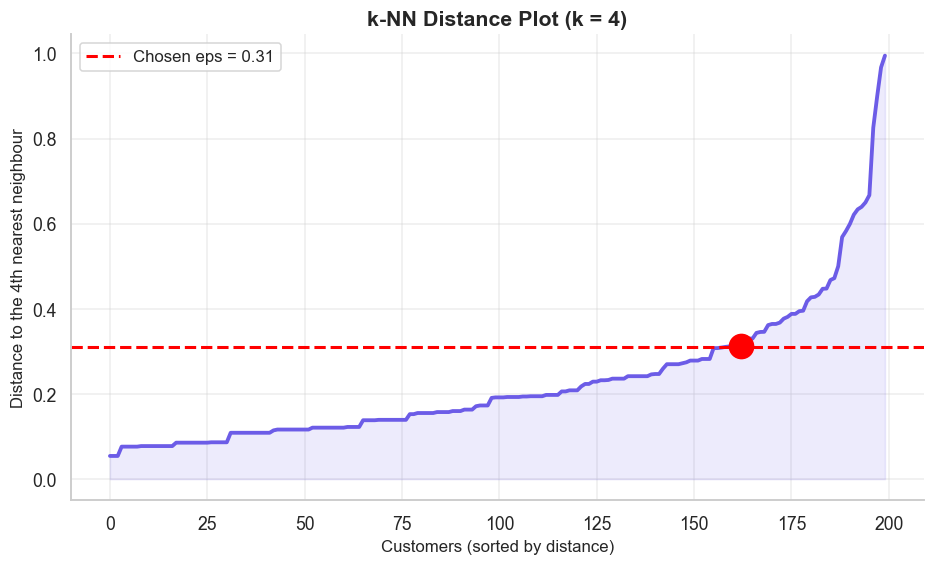

Chosen epsilon (eps) = 0.31


In [25]:
# Step 1: For every customer, find the distance to its 4th nearest neighbour
neighbors = NearestNeighbors(n_neighbors=4)
neighbors.fit(X_2d_scaled)
distances, _ = neighbors.kneighbors(X_2d_scaled)
k_distances = np.sort(distances[:, -1])            # last column = 4th neighbour, sorted small -> large

# Step 2: Find the elbow of this curve (the point where it bends sharply upward)
knee_index = find_elbow(np.arange(len(k_distances)), k_distances)
eps_optimal = round(float(k_distances[knee_index]), 2)

# Step 3: Draw the k-distance plot
plt.figure(figsize=(10, 5.5))
plt.plot(k_distances, color=COLORS[0], linewidth=2.5)
plt.fill_between(range(len(k_distances)), k_distances, alpha=0.12, color=COLORS[0])
plt.axhline(eps_optimal, color="red", linestyle="--", linewidth=2, label=f"Chosen eps = {eps_optimal}")
plt.scatter(knee_index, k_distances[knee_index], s=250, color="red", zorder=5)
plt.title("k-NN Distance Plot (k = 4)")
plt.xlabel("Customers (sorted by distance)")
plt.ylabel("Distance to the 4th nearest neighbour")
plt.legend(fontsize=11)
save_fig("12_knn_distance_plot")
plt.show()

print(f"Chosen epsilon (eps) = {eps_optimal}")

**Explanation :- ** 

For every customer the distance to its 4th nearest neighbour (the point itself counts as the first, which matches `min_samples = 4` in DBSCAN) is computed, sorted and plotted. Most points lie in dense areas (small, flat distances); the curve then **bends sharply upward** for isolated points. The bend – the "elbow" – is where "dense" turns into "sparse", so the distance at that point is a good **ε**. It is detected automatically and marked in red (typically a few tenths in scaled units).

**Justification :-** 

ε just below the sharp rise keeps genuinely dense neighbourhoods together while leaving out the few points whose neighbours are far away.

## 5.2 Train the DBSCAN Model

In [26]:
# Train DBSCAN with the epsilon we found and min_samples = 4
dbscan_first = DBSCAN(eps=eps_optimal, min_samples=4, metric="euclidean")
df["DBSCAN_Cluster"] = dbscan_first.fit_predict(X_2d_scaled)       # label -1 means Noise

# Count clusters (do not count the noise label -1) and noise points
unique_labels = set(df["DBSCAN_Cluster"])
n_clusters_db = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = int((df["DBSCAN_Cluster"] == -1).sum())

print(f"(a) Number of clusters found (excluding noise): {n_clusters_db}")
print(f"(b) Noise points: {n_noise}  ({n_noise / len(df) * 100:.1f}% of all customers)")
print("\nCustomers per label (-1 = noise):", df["DBSCAN_Cluster"].value_counts().sort_index().to_dict())

(a) Number of clusters found (excluding noise): 7
(b) Noise points: 19  (9.5% of all customers)

Customers per label (-1 = noise): {-1: 19, 0: 16, 1: 12, 2: 7, 3: 88, 4: 32, 5: 23, 6: 3}


**Explanation :-** 

DBSCAN is trained with the ε from the k-distance plot and `min_samples = 4`. Unlike K-Means, DBSCAN chooses the number of clusters by itself and labels low-density points as **noise (`-1`)**. The printout reports the number of clusters (excluding noise) and how many customers were treated as noise. Depending on ε, DBSCAN may merge touching groups (fewer clusters than K-Means) or leave fringe customers unassigned – the next step tunes this systematically.

## 5.3 Tune DBSCAN Hyperparameters (Grid Search)

Valid combinations (>= 2 clusters and < 30% noise), best first:


,eps,min_samples,Clusters,Noise %,Silhouette
0,0.4,10,4,25.5,0.5972
1,0.4,7,4,10.0,0.4946
2,0.4,5,4,7.5,0.4781
3,0.2,3,13,22.0,0.4697
4,0.4,4,3,7.0,0.4576
5,0.4,3,4,5.0,0.3954


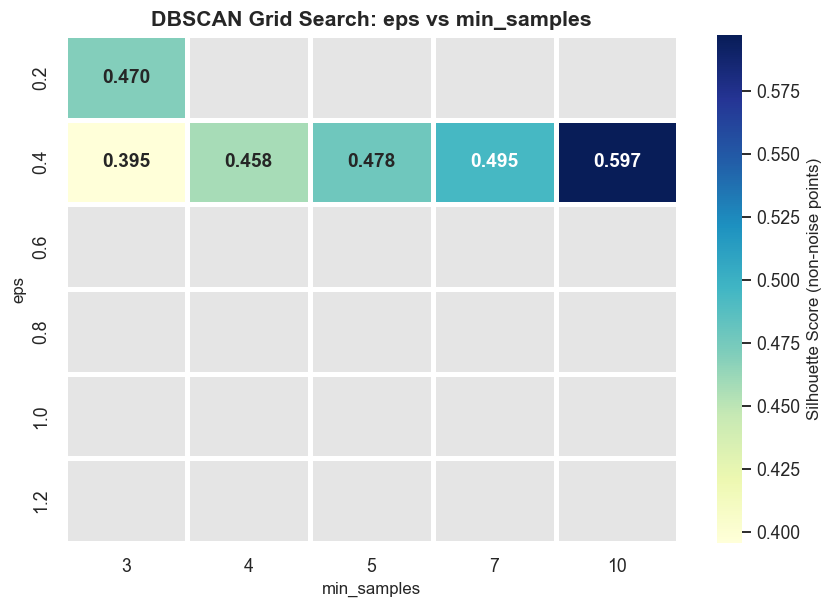

In [42]:
eps_values = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
min_samples_values = [3, 4, 5, 7, 10]

results = []                                        

for eps in eps_values:
    for min_samples in min_samples_values:
        # Train DBSCAN with this pair of values
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_2d_scaled)

        not_noise = labels != -1                                     
        n_clusters = len(set(labels[not_noise]))
        noise_percent = (labels == -1).mean() * 100

        # A combination is valid only if it has >= 2 clusters and < 30% noise
        if n_clusters >= 2 and noise_percent < 30:
            score = silhouette_score(X_2d_scaled[not_noise], labels[not_noise])  
        else:
            score = np.nan                                           # NaN = invalid combination

        results.append({"eps": eps, "min_samples": min_samples, "Clusters": n_clusters,
                        "Noise %": round(noise_percent, 1), "Silhouette": score})

grid_df = pd.DataFrame(results)

print("Valid combinations (>= 2 clusters and < 30% noise), best first:")
display(grid_df.dropna(subset=["Silhouette"]).sort_values("Silhouette", ascending=False).round(4).reset_index(drop=True))


# Heatmap: rows = eps, columns = min_samples, colour = silhouette (grey = invalid)
pivot = grid_df.pivot(index="eps", columns="min_samples", values="Silhouette")
plt.figure(figsize=(9, 6))
ax = sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", mask=pivot.isna(),
                 linewidths=2, linecolor="white", annot_kws={"fontweight": "bold"},
                 cbar_kws={"label": "Silhouette Score (non-noise points)"})
ax.set_facecolor("#E5E5E5")                      
ax.grid(False)                                    
plt.title("DBSCAN Grid Search: eps vs min_samples")
plt.xlabel("min_samples")
plt.ylabel("eps")
save_fig("13_dbscan_grid_heatmap")
plt.show()

**Explanation :-** 

Thirty DBSCAN models (6 ε values × 5 `min_samples` values) are trained. A combination is considered **valid** only if it finds **at least 2 clusters and fewer than 30 % noise**; for valid ones the silhouette score is computed on **non-noise points only** (noise has no cluster to be compared with). Invalid combinations are left as `NaN` and appear as grey cells in the heatmap. Small ε values produce mostly noise, very large ε values merge everything into one giant cluster – so only a band in the middle of the grid survives.

In [28]:
# Choose the combination with the highest silhouette score
valid_grid = grid_df.dropna(subset=["Silhouette"])

if len(valid_grid) == 0:
    # Safety net: if no combination is valid, use the eps from the k-distance plot
    print("No valid combination found - using the epsilon from the k-distance plot.")
    eps_final = eps_optimal
    ms_final = 4
else:
    best_row = valid_grid.sort_values("Silhouette", ascending=False).iloc[0]
    eps_final = float(best_row["eps"])
    ms_final = int(best_row["min_samples"])
    print(f"Best combination -> eps = {eps_final}, min_samples = {ms_final}  (silhouette = {best_row['Silhouette']:.4f})")

# Train the final DBSCAN model and overwrite the labels
dbscan_final = DBSCAN(eps=eps_final, min_samples=ms_final, metric="euclidean")
df["DBSCAN_Cluster"] = dbscan_final.fit_predict(X_2d_scaled)

n_clusters_db = len(set(df["DBSCAN_Cluster"]) - {-1})
n_noise = int((df["DBSCAN_Cluster"] == -1).sum())
noise_pct_db = n_noise / len(df) * 100

print(f"\nFinal DBSCAN: {n_clusters_db} clusters, {n_noise} noise points ({noise_pct_db:.1f}%)")
print("Customers per label (-1 = noise):", df["DBSCAN_Cluster"].value_counts().sort_index().to_dict())

Best combination -> eps = 0.4, min_samples = 10  (silhouette = 0.5972)

Final DBSCAN: 4 clusters, 51 noise points (25.5%)
Customers per label (-1 = noise): {-1: 51, 0: 11, 1: 87, 2: 29, 3: 22}


**Explanation :-** 

The combination with the **highest silhouette score** among the valid ones is selected and DBSCAN is re-trained with it; `DBSCAN_Cluster` is overwritten with these final labels. If no combination satisfied the rules, the code falls back to the ε from the k-distance plot so the notebook never breaks. *Note:* this criterion rewards tight, compact clusters and ignores noise points, so a slightly better silhouette can come at the price of more unassigned customers – this is why the noise percentage is reported next to it.

## 5.4 Visualise & Profile the DBSCAN Clusters

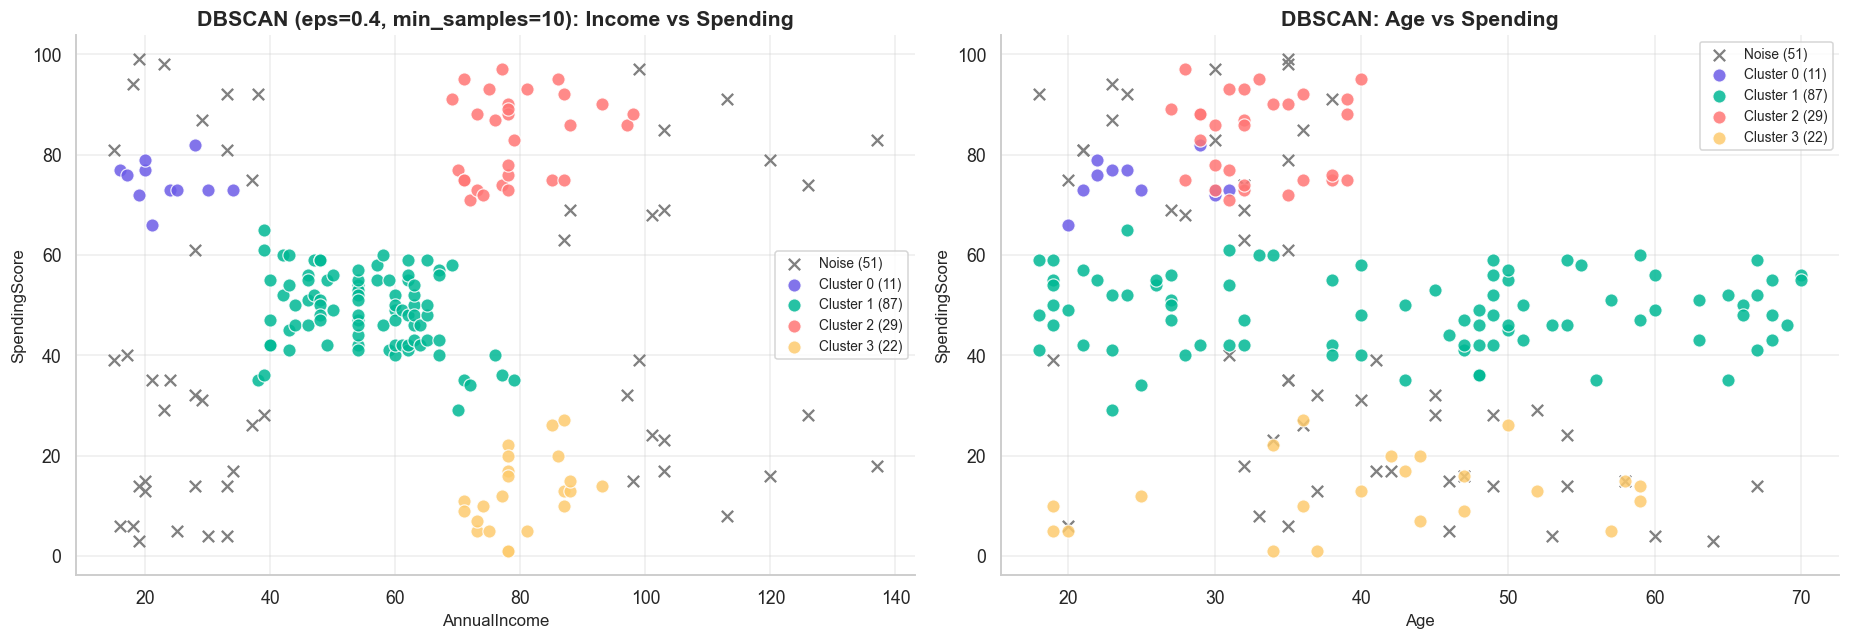

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
plot_clusters(axes[0], df, "AnnualIncome", "SpendingScore", "DBSCAN_Cluster",
              f"DBSCAN (eps={eps_final}, min_samples={ms_final}): Income vs Spending")
plot_clusters(axes[1], df, "Age", "SpendingScore", "DBSCAN_Cluster",
              "DBSCAN: Age vs Spending")

plt.tight_layout()
save_fig("14_dbscan_clusters")
plt.show()

**Explanation :-** 

DBSCAN clusters are coloured as before, while **noise points are grey ✕ markers**. On the Income–Spending plane the dense corner groups are recovered as clusters, and the noise points tend to sit on the **borders between groups** (and in the sparse tails), not far away from everyone.

In [43]:
# Profile of the real clusters (noise is left out)
core = df[df["DBSCAN_Cluster"] != -1]
db_profile = core.groupby("DBSCAN_Cluster").agg(
    Customers=("CustomerID", "count"),
    Age=("Age", "mean"),
    AnnualIncome=("AnnualIncome", "mean"),
    SpendingScore=("SpendingScore", "mean"),
).round(2)
db_profile = db_profile.sort_values("SpendingScore", ascending=False)

db_persona_map = name_personas(db_profile)
df["DBSCAN_Persona"] = df["DBSCAN_Cluster"].map(db_persona_map).fillna("Noise / Unclassified")
db_profile["Persona"] = db_profile.index.map(db_persona_map)

print("DBSCAN cluster profile (noise excluded):")
display(db_profile)

# Profile of the noise shoppers
noise = df[df["DBSCAN_Cluster"] == -1]
print(f"\nNumber of noise shoppers: {len(noise)}")

if len(noise) > 0:
    noise_profile = noise[["Age", "AnnualIncome", "SpendingScore"]].mean().round(2).to_frame("Noise shoppers (mean)")
    noise_profile["All customers (mean)"] = df[["Age", "AnnualIncome", "SpendingScore"]].mean().round(2)
    display(noise_profile)

    print("Spending category of the noise shoppers (%):")
    print((noise["SpendingCategory"].value_counts(normalize=True) * 100).round(1).to_string())
    print("\nIncome group of the noise shoppers (%):")
    print((noise["IncomeGroup"].value_counts(normalize=True) * 100).round(1).to_string())
else:
    print("No noise points with the final parameters.")

DBSCAN cluster profile (noise excluded):


,Customers,Age,AnnualIncome,SpendingScore,Persona
DBSCAN_Cluster,,,,,
2,29,32.93,79.24,83.62,Big Spenders
0,11,25.18,23.09,74.64,Young Aspirers
1,87,42.80,55.41,48.82,Mainstream Shoppers
3,22,41.00,80.18,12.68,Careful Spenders



Number of noise shoppers: 51


,Noise shoppers (mean),All customers (mean)
Age,37.49,38.85
AnnualIncome,58.33,60.56
SpendingScore,44.47,50.20


Spending category of the noise shoppers (%):
SpendingCategory
Low       51.0
High      35.3
Medium    13.7

Income group of the noise shoppers (%):
IncomeGroup
Low       60.8
High      39.2
Medium     0.0


**Explanation :-** 

Clusters are profiled without the noise, and the noise shoppers get a **separate mean profile** compared with the overall average.

**Who are the noise shoppers ?** Read the two printed tables together. In most runs the noise shoppers are *not* extreme outliers : their averages sit fairly close to the overall mean and many fall in the **medium spending / medium income** categories – shoppers located **between** the dense segments (e.g. a mid-income customer with a spending score of 60–65 who is neither a "Big Spender" nor "Mainstream"). A few genuinely unusual customers (for example the very highest incomes) can also appear. So the noise mostly reflects **shoppers who do not fit a clean mainstream pattern** rather than unusual people – confirm this with your own output before quoting it.

**Nuance :-** 

DBSCAN defines clusters only by density, so it (1) may merge neighbouring groups that touch each other (fewer clusters than K-Means), and (2) flags fringe / in-between shoppers as noise. For a marketing team this is useful information – these "in-between" customers can be targeted with generic mall-wide offers – but it also means DBSCAN alone would leave part of the customer base without a persona.

---
# 📊 Step 6: Algorithm Comparison & Business Interpretation

## 6.1 Internal Metrics Comparison Table

,Hyperparameters,Clusters,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),Noise %,Average rank,Overall rank
Algorithm,,,,,,,,
K-Means,"k=5, init=k-means++, n_init=20",5,0.555,0.572,248.649,0.0,2.0,2
Agglomerative,"n_clusters=5, linkage=ward",5,0.554,0.578,244.410,0.0,3.0,3
DBSCAN,"eps=0.4, min_samples=10",4,0.597,0.473,263.612,25.5,1.0,1



Rank of each algorithm on each metric (1 = best):


,Silhouette rank,Davies-Bouldin rank,Calinski-Harabasz rank
Algorithm,,,
K-Means,2.0,2.0,2.0
Agglomerative,3.0,3.0,3.0
DBSCAN,1.0,1.0,1.0



🏆 Best algorithm by the three internal metrics: DBSCAN


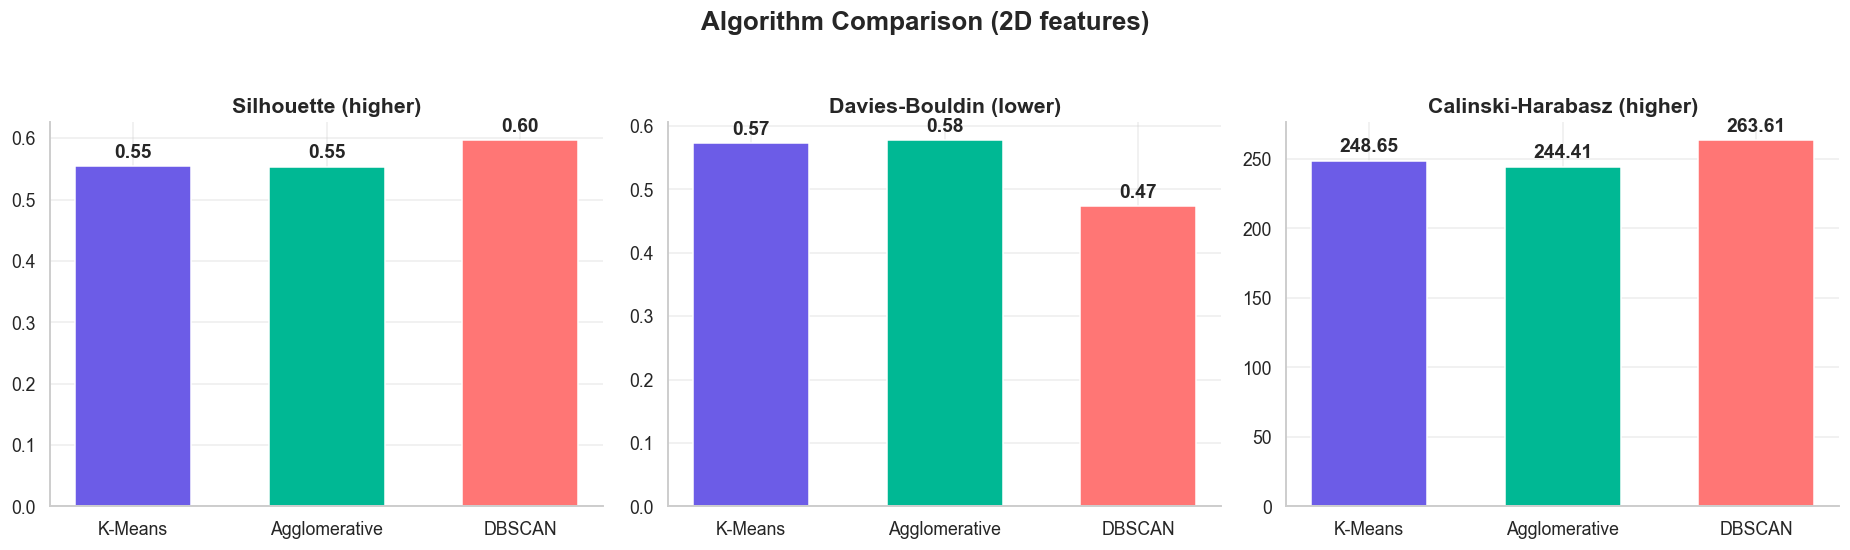

In [44]:
# A small function that returns the 3 evaluation scores for any clustering result
def get_scores(X, labels):
    silhouette = silhouette_score(X, labels)               # higher is better
    davies_bouldin = davies_bouldin_score(X, labels)       # lower is better
    calinski = calinski_harabasz_score(X, labels)          # higher is better
    return silhouette, davies_bouldin, calinski


# Scores of each algorithm (all on the same 2D scaled data)
km_scores = get_scores(X_2d_scaled, df["KMeans_Cluster"])
agg_scores = get_scores(X_2d_scaled, df["Agg_Cluster"])

# DBSCAN: leave out the noise points, because noise has no cluster
not_noise = (df["DBSCAN_Cluster"] != -1).values
db_scores = get_scores(X_2d_scaled[not_noise], df.loc[not_noise, "DBSCAN_Cluster"])

# Put everything in one table
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative", "DBSCAN"],
    "Hyperparameters": [f"k={k_optimal}, init=k-means++, n_init=20",
                        f"n_clusters={n_chosen}, linkage={best_linkage}",
                        f"eps={eps_final}, min_samples={ms_final}"],
    "Clusters": [k_optimal, n_chosen, n_clusters_db],
    "Silhouette (higher)": [km_scores[0], agg_scores[0], db_scores[0]],
    "Davies-Bouldin (lower)": [km_scores[1], agg_scores[1], db_scores[1]],
    "Calinski-Harabasz (higher)": [km_scores[2], agg_scores[2], db_scores[2]],
    "Noise %": [0.0, 0.0, noise_pct_db],
}).set_index("Algorithm")

# Rank the algorithms on each metric (1 = best) and take the average rank
rank_table = pd.DataFrame({
    "Silhouette rank": comparison["Silhouette (higher)"].rank(ascending=False),
    "Davies-Bouldin rank": comparison["Davies-Bouldin (lower)"].rank(ascending=True),
    "Calinski-Harabasz rank": comparison["Calinski-Harabasz (higher)"].rank(ascending=False),
})
comparison["Average rank"] = rank_table.mean(axis=1).round(2)
comparison["Overall rank"] = comparison["Average rank"].rank(method="min").astype(int)

display(comparison.round(3))
print("\nRank of each algorithm on each metric (1 = best):")
display(rank_table)

# Best algorithm = lowest average rank (silhouette breaks a tie)
best_algo = comparison.sort_values(["Average rank", "Silhouette (higher)"], ascending=[True, False]).index[0]
print(f"\n🏆 Best algorithm by the three internal metrics: {best_algo}")

# Bar charts to compare the algorithms visually
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
metric_names = ["Silhouette (higher)", "Davies-Bouldin (lower)", "Calinski-Harabasz (higher)"]
for i in range(3):
    bars = axes[i].bar(comparison.index, comparison[metric_names[i]], color=COLORS[:3], edgecolor="white", width=0.6)
    axes[i].bar_label(bars, fmt="%.2f", padding=3, fontweight="bold")
    axes[i].set_title(metric_names[i])
fig.suptitle("Algorithm Comparison (2D features)", fontsize=17, fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("15_algorithm_comparison")
plt.show()

**Explanation :-** 

All three algorithms are evaluated on the **same 2D scaled data** with three internal metrics:

* **Silhouette Score** (−1 to 1, higher = better) – how much closer points are to their own cluster than to the nearest other one.
* **Davies-Bouldin Index** (lower = better) – average similarity between each cluster and its most similar neighbour.
* **Calinski-Harabasz Index** (higher = better) – ratio of between-cluster to within-cluster dispersion.

Each algorithm is ranked on every metric and the ranks are averaged to give an overall winner. **K-Means and Ward-linkage Agglomerative clustering are usually almost tied** on this data (both look for compact, round groups). DBSCAN can show very high scores, but that is partly because its metrics are calculated **after removing noise points** and (with the winning grid setting) on fewer, tighter clusters – so a high DBSCAN score must be read together with its noise percentage and cluster count. *Conclusion:* the most well-separated and compact **and** complete segmentation (every customer gets a persona) comes from the top-ranked model printed above, with K-Means/Ward as the practical business choice. The bar charts under the table show the same comparison visually.

## 6.2 Cluster Stability Check for K-Means

In [32]:
seeds = [0, 7, 21, 42, 99]
stability_scores = []

for seed in seeds:
    model = KMeans(n_clusters=k_optimal, init="k-means++", n_init=20, max_iter=500, random_state=seed)
    labels = model.fit_predict(X_2d_scaled)
    stability_scores.append(silhouette_score(X_2d_scaled, labels))

stability_table = pd.DataFrame({"random_state": seeds, "Silhouette": np.round(stability_scores, 5)})
display(stability_table.set_index("random_state"))

stab_mean = np.mean(stability_scores)
stab_std = np.std(stability_scores)
print(f"Silhouette over 5 runs: {stab_mean:.4f} ± {stab_std:.4f}")

,Silhouette
random_state,
0,0.55466
7,0.55466
21,0.55466
42,0.55466
99,0.55466


Silhouette over 5 runs: 0.5547 ± 0.0000


**Explanation :-** 

K-Means starts from random centroids, so different seeds *can* give different answers. The model is retrained with five seeds (0, 7, 21, 42, 99) and the mean ± standard deviation of the silhouette score is reported. A standard deviation of ≈ 0 (identical or nearly identical scores) shows the result is **stable**: with `k-means++` initialisation and `n_init = 20` restarts, K-Means finds the same five well-separated groups every time on this small, clean dataset, so the segmentation does not depend on luck.

## 6.3 Business Recommendation

In [45]:
# Take the numbers we need from the results above
best = comparison.loc[best_algo]
km_row = comparison.loc["K-Means"]

# Build one text block for every K-Means segment (persona, size, description, strategy)
segment_texts = []
number = 1
for cluster_id, row in km_profile.iterrows():
    description, strategy = get_info(row["Persona"])
    text = (f"**{number}. {row['Persona']}** ({int(row['Customers'])} customers · avg income {row['AnnualIncome']:.0f}k$ · "
            f"spending score {row['SpendingScore']:.0f} · avg age {row['Age']:.0f})  \n"
            f"*Description:* {description}  \n"
            f"*Strategy:* {strategy}\n")
    segment_texts.append(text)
    number = number + 1
segments_md = "\n".join(segment_texts)

# Write the recommendation. Every number comes from the results above.
business_reco = f"""
### 📝 Business Recommendation

**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity  
**From:** Retail Analytics Team  
**Subject:** Shopper segmentation and recommended actions

#### 1. Recommended algorithm
Based on 200 customers clustered on annual income and spending score, I recommend **K-Means with k = {k_optimal}**.
It scored a silhouette of **{km_row['Silhouette (higher)']:.3f}**, a Davies-Bouldin index of **{km_row['Davies-Bouldin (lower)']:.3f}**
and a Calinski-Harabasz index of **{km_row['Calinski-Harabasz (higher)']:.1f}**, with 0 % noise, so every customer receives a persona.
The top-ranked algorithm on the three internal metrics was **{best_algo}** (silhouette {best['Silhouette (higher)']:.3f},
DBI {best['Davies-Bouldin (lower)']:.3f}, CH {best['Calinski-Harabasz (higher)']:.1f}, noise {best['Noise %']:.1f} %).
Hierarchical (Ward) agrees with K-Means on {agreement_pct:.1f} % of customers, and K-Means is stable across seeds
(silhouette {stab_mean:.3f} ± {stab_std:.3f}). K-Means is also the model that can label *new* visitors instantly, which is why it is deployed.
DBSCAN is best used as a diagnostic tool: it found {n_clusters_db} dense cluster(s) and flagged {noise_pct_db:.1f} % of shoppers as "in-between" noise.

#### 2. Customer segments and recommended strategies
{segments_md}

#### 3. Additional data that would improve segmentation
* **Purchase category data** (fashion, electronics, F&B, grocery) to see *what* each segment buys, not only how much.
* **Visit frequency and dwell time** from footfall sensors / Wi-Fi analytics, to separate loyal regulars from occasional visitors.
* **Loyalty-app behaviour** (coupon redemption, app opens, points usage) to measure responsiveness to offers.
* **Basket size, payment mode and timing** (weekday vs weekend, festival season) for better campaign timing.
"""
display(Markdown(business_reco))


### 📝 Business Recommendation

**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity  
**From:** Retail Analytics Team  
**Subject:** Shopper segmentation and recommended actions

#### 1. Recommended algorithm
Based on 200 customers clustered on annual income and spending score, I recommend **K-Means with k = 5**.
It scored a silhouette of **0.555**, a Davies-Bouldin index of **0.572**
and a Calinski-Harabasz index of **248.6**, with 0 % noise, so every customer receives a persona.
The top-ranked algorithm on the three internal metrics was **DBSCAN** (silhouette 0.597,
DBI 0.473, CH 263.6, noise 25.5 %).
Hierarchical (Ward) agrees with K-Means on 98.0 % of customers, and K-Means is stable across seeds
(silhouette 0.555 ± 0.000). K-Means is also the model that can label *new* visitors instantly, which is why it is deployed.
DBSCAN is best used as a diagnostic tool: it found 4 dense cluster(s) and flagged 25.5 % of shoppers as "in-between" noise.

#### 2. Customer segments and recommended strategies
**1. Big Spenders** (39 customers · avg income 87k$ · spending score 82 · avg age 33)  
*Description:* High income and high spending - the premium core of the mall.  
*Strategy:* Install a premium lounge with curated luxury-brand pop-ups near the food court, plus invite-only previews and personal-shopper service.

**2. Young Aspirers** (22 customers · avg income 26k$ · spending score 79 · avg age 25)  
*Description:* Low income but very high spending - young, trend-driven shoppers.  
*Strategy:* Create a youth zone (fast fashion, gaming, cafes) with student discounts, UPI cashback and Instagram-worthy pop-ups.

**3. Mainstream Shoppers** (81 customers · avg income 55k$ · spending score 50 · avg age 43)  
*Description:* Medium income and medium spending - the largest 'Westside-type' everyday segment.  
*Strategy:* Place mid-range brand zones around the central atrium and run seasonal sales and family bundle offers.

**4. Budget Shoppers** (23 customers · avg income 26k$ · spending score 21 · avg age 45)  
*Description:* Low income and low spending - value-for-money and deal seekers.  
*Strategy:* Place value-for-money stores near mall entrances and send ₹50-off coupons and BOGO offers via the mall app.

**5. Careful Spenders** (35 customers · avg income 88k$ · spending score 17 · avg age 41)  
*Description:* High income but low spending - wealthy yet frugal, an untapped opportunity.  
*Strategy:* Use quality- and warranty-led messaging, premium electronics/home showcases and personalised app offers to raise their visit value.


#### 3. Additional data that would improve segmentation
* **Purchase category data** (fashion, electronics, F&B, grocery) to see *what* each segment buys, not only how much.
* **Visit frequency and dwell time** from footfall sensors / Wi-Fi analytics, to separate loyal regulars from occasional visitors.
* **Loyalty-app behaviour** (coupon redemption, app opens, points usage) to measure responsiveness to offers.
* **Basket size, payment mode and timing** (weekday vs weekend, festival season) for better campaign timing.


**Explanation :-** 

This cell writes the 1-page recommendation addressed to the Retail Operations Director. It is generated with Python f-strings, so **every number quoted (silhouette, Davies-Bouldin, Calinski-Harabasz, agreement %, stability, noise %) comes straight from the results computed above** – nothing is typed by hand and nothing can go out of date if the notebook is re-run. It covers: (1) the recommended algorithm and why, (2) each segment with a one-line description and one concrete strategy, and (3) the extra data that would improve the segmentation.

---
# 🚀 Step 7: Pipeline, Deployment & GitHub Submission

## 7.1 Save the Final Clustering Pipeline

In [34]:
# We deploy the 2D K-Means model, because K-Means can predict the cluster of NEW customers
best_model = kmeans_2d

# Save the scaler and the model as .pkl files
joblib.dump(scaler_2d, SCALER_FILE)
joblib.dump(best_model, MODEL_FILE)
print("Saved:", SCALER_FILE, "and", MODEL_FILE)

# Load them back from the disk to prove that the files work on their own
scaler_loaded = joblib.load(SCALER_FILE)
model_loaded = joblib.load(MODEL_FILE)

# Get the cluster centres (real income / spending values) and name every cluster
centers_df = pd.DataFrame(scaler_loaded.inverse_transform(model_loaded.cluster_centers_),
                          columns=["AnnualIncome", "SpendingScore"])
deploy_persona_map = name_personas(centers_df)
print("Persona of each saved cluster:", deploy_persona_map)

Saved: ../mall_scaler.pkl and ../mall_segmentation_model.pkl
Persona of each saved cluster: {0: 'Mainstream Shoppers', 1: 'Big Spenders', 2: 'Young Aspirers', 3: 'Careful Spenders', 4: 'Budget Shoppers'}


**Explanation :-** The fitted `StandardScaler` and the final model are saved with `joblib`. *Design decision:* DBSCAN and Agglomerative clustering have no `predict()` method for new data points, whereas **K-Means does** – so the 2D K-Means model is the one deployed (it is also the recommended model). The files are immediately reloaded to prove they work stand-alone, and persona names are re-derived from the saved cluster centres, so the two `.pkl` files are all that is needed to classify a new shopper.

In [35]:
def classify_shopper(age, annual_income, spending_score, gender=None):
    """Tell the cluster number and persona of a NEW shopper.

    age            : age of the customer (kept for completeness, the 2D model does not use it)
    annual_income  : annual income in k$ (same unit as the dataset)
    spending_score : spending score from 1 to 100
    gender         : optional - 'Female' or 'Male' (the 2D model does not use it)
    """
    # Step 1: check that the inputs make sense
    if spending_score < 1 or spending_score > 100:
        raise ValueError("spending_score must be between 1 and 100")
    if annual_income < 0 or age < 0:
        raise ValueError("age and annual_income cannot be negative")

    # Step 2: put the income and spending in a table (same column names as training)
    new_customer = pd.DataFrame([[annual_income, spending_score]], columns=["AnnualIncome", "SpendingScore"])

    # Step 3: scale it with the saved scaler and predict the cluster with the saved model
    new_scaled = scaler_loaded.transform(new_customer)
    cluster = int(model_loaded.predict(new_scaled)[0])

    # Step 4: return the cluster number and its persona name
    return cluster, deploy_persona_map[cluster]


# ---- Test the function on 5 hypothetical new shoppers (income in k$, like the dataset)
new_shoppers = [
    {"Age": 22, "Gender": "Female", "AnnualIncome": 30, "SpendingScore": 85},
    {"Age": 45, "Gender": "Male",   "AnnualIncome": 95, "SpendingScore": 15},
    {"Age": 35, "Gender": "Female", "AnnualIncome": 90, "SpendingScore": 88},
    {"Age": 60, "Gender": "Male",   "AnnualIncome": 20, "SpendingScore": 10},
    {"Age": 30, "Gender": "Female", "AnnualIncome": 55, "SpendingScore": 50},
]

test_results = []
for shopper in new_shoppers:
    cluster, persona = classify_shopper(shopper["Age"], shopper["AnnualIncome"], shopper["SpendingScore"], shopper["Gender"])
    shopper["Cluster"] = cluster
    shopper["Persona"] = persona
    test_results.append(shopper)

display(pd.DataFrame(test_results))

,Age,Gender,AnnualIncome,SpendingScore,Cluster,Persona
0,22,Female,30,85,2,Young Aspirers
1,45,Male,95,15,3,Careful Spenders
2,35,Female,90,88,1,Big Spenders
3,60,Male,20,10,4,Budget Shoppers
4,30,Female,55,50,0,Mainstream Shoppers


**Explanation :-** 

`classify_shopper()` takes a new customer's raw Age, AnnualIncome and SpendingScore (and optionally Gender), validates the inputs, scales them with the **saved scaler**, predicts the cluster with the **saved model** and returns the cluster label and persona name. Five hypothetical shoppers are tested – for example the *22-year-old female with low income (30 k$) and spending score 85* lands in the **Young Aspirers** segment, while a 35-year-old with 90 k$ income and score 88 becomes a **Big Spender**. *(The exam text mentions "₹30k"; the dataset stores income in thousands of dollars-equivalent units, so `30` is used here.)* Age and Gender are accepted for future extension but ignored by the 2D model.

## 7.2 Repository Files & GitHub Submission

In [36]:
# Files that should be present before you upload the project to GitHub
expected_files = [
    "MallShopperSegmentation_UnsupervisedLearning.ipynb",   # this notebook
    DATA_FILE,                                              # dataset
    SCALER_FILE,                                            # mall_scaler.pkl
    MODEL_FILE,                                             # mall_segmentation_model.pkl
    REPORT_FILE,                                            # summary_report.md (created in Step 7.3)
    "../requirements.txt",
    "../README.md",
]

print("Project file check (run this cell again after Step 7.3):")
for file_name in expected_files:
    if os.path.exists(file_name):
        print("  ✅", file_name)
    else:
        print("  ⬜", file_name)

print("\nSaved graphs:", sorted(os.listdir(IMAGES_DIR)))

Project file check (run this cell again after Step 7.3):
  ✅ MallShopperSegmentation_UnsupervisedLearning.ipynb
  ✅ ../Dataset/Mall_Customers.csv
  ✅ ../mall_scaler.pkl
  ✅ ../mall_segmentation_model.pkl
  ⬜ ../Summary & Report/summary_report.md
  ✅ ../requirements.txt
  ✅ ../README.md

Saved graphs: ['01_histograms.png', '02_boxplots.png', '03_gender_countplot.png', '04_bivariate_scatter.png', '05_correlation_heatmap.png', '06_gender_summary.png', '07_kmeans_elbow_silhouette.png', '08_kmeans_clusters.png', '08b_kmeans_personas.png', '09_kmeans_5d_pca.png', '10_dendrogram.png', '11_agglomerative_clusters.png', '11b_kmeans_vs_hierarchical.png', '12_knn_distance_plot.png', '13_dbscan_grid_heatmap.png', '14_dbscan_clusters.png', '15_algorithm_comparison.png']


**Explanation :-** 

A quick checklist of the files that must exist in the repository (see the folder structure at the top of the notebook). The `images/` folder holds the figures used as README screenshots. To publish the project, create a public repository named **`mall-shopper-segmentation-unsupervised-learning`** on GitHub and run the following in a terminal inside the project folder:

```bash
git init
git add .
git commit -m "Add mall shopper segmentation project (K-Means, Hierarchical, DBSCAN)"
git branch -M main
git remote add origin https://github.com/<your-username>/mall-shopper-segmentation-unsupervised-learning.git
git push -u origin main
```
Tip: make several meaningful commits (e.g. *EDA*, *K-Means*, *DBSCAN*, *README*) instead of one – it makes the repository look more professional.

## 7.3 Summary Report (`summary_report.md`)

In [37]:
# Numbers used inside the report text
n_female = int((df["Gender"] == "Female").sum())
n_male = int((df["Gender"] == "Male").sum())

# One bullet point for every segment
segment_lines = ""
for cluster_id, row in km_profile.iterrows():
    description = get_info(row["Persona"])[0]
    segment_lines += (f"* **{row['Persona']}** – {int(row['Customers'])} customers, income about {row['AnnualIncome']:.0f}k$, "
                      f"spending score about {row['SpendingScore']:.0f}, average age {row['Age']:.0f}. {description}\n")

# Does the result match business intuition?
if k_optimal == 5:
    intuition = ("The result matches business intuition: the five groups seen on the income-versus-spending "
                 "scatter plot were recovered almost exactly.")
else:
    intuition = f"The {k_optimal} segments are interpretable and consistent with the income-versus-spending scatter plot."

# Extra sentence only if DBSCAN won the ranking
if best_algo == "DBSCAN":
    db_note = (f" DBSCAN's scores are partly flattered because {noise_pct_db:.1f} % of shoppers are excluded as noise, "
               "so K-Means remains the practical choice: every customer gets a persona and new shoppers can be labelled.")
else:
    db_note = ""

summary_report = f"""# Summary Report – Mall Shopper Profiling (Unsupervised Learning)

## 1. Business Problem and Dataset
A large Indian mall chain wants to understand how visitors spend, so that it can redesign store layouts, plan targeted promotions and offer personalised loyalty rewards. I used the Kaggle *Mall Customer Segmentation* dataset: {len(df)} customers ({n_female} female, {n_male} male) with Age, Gender, Annual Income (k$) and Spending Score (1–100). There were no missing values.

## 2. Features Used: 2D vs 5D
Experiment A (2D) clustered on **AnnualIncome and SpendingScore**; Experiment B (the "5D" set) added **Age and encoded Gender**. All features were standardised because K-Means, Hierarchical clustering and DBSCAN are distance-based. K-Means gave a silhouette of {sil_2d:.3f} on the 2D set versus {sil_5d:.3f} on the richer set, so the {winner} set produced better-separated clusters. The 2D set is also easy to explain to business teams as an income-versus-spending map, so it was used for all algorithms and for deployment.

## 3. Algorithm Performance
* **K-Means** (k = {k_optimal}): silhouette {comparison.loc['K-Means', 'Silhouette (higher)']:.3f}, Davies-Bouldin {comparison.loc['K-Means', 'Davies-Bouldin (lower)']:.3f}, Calinski-Harabasz {comparison.loc['K-Means', 'Calinski-Harabasz (higher)']:.1f}.
* **Agglomerative** ({best_linkage} linkage, {n_chosen} clusters): silhouette {comparison.loc['Agglomerative', 'Silhouette (higher)']:.3f}; it agrees with K-Means on {agreement_pct:.1f} % of customers.
* **DBSCAN** (eps = {eps_final}, min_samples = {ms_final}): {n_clusters_db} clusters, {noise_pct_db:.1f} % noise, silhouette {comparison.loc['DBSCAN', 'Silhouette (higher)']:.3f} on non-noise points.

By average rank over the three internal metrics, **{best_algo}** performed best.{db_note} K-Means is stable across five random seeds (silhouette {stab_mean:.3f} ± {stab_std:.3f}). {intuition}

## 4. Shopper Segments
{segment_lines}
## 5. Next Steps
I would collect richer behavioural data (purchase categories, visit frequency from footfall sensors and loyalty-app activity), test semi-supervised methods once a few customers are labelled by the marketing team, and build a real-time persona-tagging API for the mall app on top of the saved scaler and model, so offers can be personalised at the moment a shopper walks in.
"""

# Save the report as a .md file
with open(REPORT_FILE, "w", encoding="utf-8") as file:
    file.write(summary_report)

print(f"summary_report.md saved in '{REPORT_DIR}' ({len(summary_report.split())} words)")
display(Markdown(summary_report))

summary_report.md saved in '../Summary & Report' (478 words)


# Summary Report – Mall Shopper Profiling (Unsupervised Learning)

## 1. Business Problem and Dataset
A large Indian mall chain wants to understand how visitors spend, so that it can redesign store layouts, plan targeted promotions and offer personalised loyalty rewards. I used the Kaggle *Mall Customer Segmentation* dataset: 200 customers (112 female, 88 male) with Age, Gender, Annual Income (k$) and Spending Score (1–100). There were no missing values.

## 2. Features Used: 2D vs 5D
Experiment A (2D) clustered on **AnnualIncome and SpendingScore**; Experiment B (the "5D" set) added **Age and encoded Gender**. All features were standardised because K-Means, Hierarchical clustering and DBSCAN are distance-based. K-Means gave a silhouette of 0.555 on the 2D set versus 0.314 on the richer set, so the 2D set produced better-separated clusters. The 2D set is also easy to explain to business teams as an income-versus-spending map, so it was used for all algorithms and for deployment.

## 3. Algorithm Performance
* **K-Means** (k = 5): silhouette 0.555, Davies-Bouldin 0.572, Calinski-Harabasz 248.6.
* **Agglomerative** (ward linkage, 5 clusters): silhouette 0.554; it agrees with K-Means on 98.0 % of customers.
* **DBSCAN** (eps = 0.4, min_samples = 10): 4 clusters, 25.5 % noise, silhouette 0.597 on non-noise points.

By average rank over the three internal metrics, **DBSCAN** performed best. DBSCAN's scores are partly flattered because 25.5 % of shoppers are excluded as noise, so K-Means remains the practical choice: every customer gets a persona and new shoppers can be labelled. K-Means is stable across five random seeds (silhouette 0.555 ± 0.000). The result matches business intuition: the five groups seen on the income-versus-spending scatter plot were recovered almost exactly.

## 4. Shopper Segments
* **Big Spenders** – 39 customers, income about 87k$, spending score about 82, average age 33. High income and high spending - the premium core of the mall.
* **Young Aspirers** – 22 customers, income about 26k$, spending score about 79, average age 25. Low income but very high spending - young, trend-driven shoppers.
* **Mainstream Shoppers** – 81 customers, income about 55k$, spending score about 50, average age 43. Medium income and medium spending - the largest 'Westside-type' everyday segment.
* **Budget Shoppers** – 23 customers, income about 26k$, spending score about 21, average age 45. Low income and low spending - value-for-money and deal seekers.
* **Careful Spenders** – 35 customers, income about 88k$, spending score about 17, average age 41. High income but low spending - wealthy yet frugal, an untapped opportunity.

## 5. Next Steps
I would collect richer behavioural data (purchase categories, visit frequency from footfall sensors and loyalty-app activity), test semi-supervised methods once a few customers are labelled by the marketing team, and build a real-time persona-tagging API for the mall app on top of the saved scaler and model, so offers can be personalised at the moment a shopper walks in.


**Explanation:** The ~400–500-word summary report is written to `summary_report.md` by the notebook itself, again using values computed earlier (dataset size, silhouette scores, best algorithm, agreement %, stability, personas), so the report always matches the actual results. It answers the exam's five questions: business problem and dataset, features (2D vs 5D), best algorithm and whether it matches business intuition, one description per segment, and next steps.

In [38]:
# Final check: are all the project files present?
for file_name in expected_files:
    if os.path.exists(file_name):
        print("✅", file_name)
    else:
        print("⬜", file_name)

✅ MallShopperSegmentation_UnsupervisedLearning.ipynb
✅ ../Dataset/Mall_Customers.csv
✅ ../mall_scaler.pkl
✅ ../mall_segmentation_model.pkl
✅ ../Summary & Report/summary_report.md
✅ ../requirements.txt
✅ ../README.md


---
## ✅ Conclusion
* The income–spending plane contains **five natural shopper segments**, recovered consistently by K-Means and Ward-linkage clustering.
* **K-Means (k = 5)** is stable, complete (no noise) and deployable; **DBSCAN** adds insight about "in-between" shoppers but leaves them unlabelled.
* Each persona has a concrete retail strategy, and the saved scaler + model can tag new shoppers in real time via `classify_shopper()`.
